In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
data_path = Path("../data/raw/Online Retail.xlsx")

df = pd.read_excel(data_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [13]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
# ============================================================
# RETAIL CUSTOMER INTELLIGENCE
# STEP 6: DATA QUALITY ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

# 1. DATASET OVERVIEW
print("=" * 60)
print("1. DATASET OVERVIEW")
print("=" * 60)

print(f"Total rows       : {df.shape[0]:,}")
print(f"Total columns    : {df.shape[1]}")
print(f"Memory usage     : {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")


# 2. COLUMN INFORMATION
print("\n" + "=" * 60)
print("2. COLUMN INFORMATION")
print("=" * 60)

column_info = pd.DataFrame({
    "Data_Type": df.dtypes.astype(str),
    "Non_Null_Count": df.notna().sum(),
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
})

print(column_info.to_string())


# 3. DUPLICATE RECORDS
print("\n" + "=" * 60)
print("3. DUPLICATE RECORD ANALYSIS")
print("=" * 60)

duplicate_count = df.duplicated().sum()

print(f"Total duplicate rows : {duplicate_count:,}")
print(
    f"Duplicate percentage : "
    f"{duplicate_count / len(df) * 100:.2f}%"
)


# 4. CANCELLATION ANALYSIS
print("\n" + "=" * 60)
print("4. CANCELLATION ANALYSIS")
print("=" * 60)

invoice_numbers = df["InvoiceNo"].astype("string").str.strip()

cancellation_mask = invoice_numbers.str.startswith(
    "C",
    na=False
)

cancellation_count = cancellation_mask.sum()

print(f"Cancellation records : {cancellation_count:,}")
print(
    f"Cancellation percentage : "
    f"{cancellation_count / len(df) * 100:.2f}%"
)


# 5. QUANTITY ANALYSIS
print("\n" + "=" * 60)
print("5. QUANTITY ANALYSIS")
print("=" * 60)

negative_quantity_count = (df["Quantity"] < 0).sum()
zero_quantity_count = (df["Quantity"] == 0).sum()
positive_quantity_count = (df["Quantity"] > 0).sum()

print(f"Negative quantities : {negative_quantity_count:,}")
print(f"Zero quantities     : {zero_quantity_count:,}")
print(f"Positive quantities : {positive_quantity_count:,}")


# 6. UNIT PRICE ANALYSIS
print("\n" + "=" * 60)
print("6. UNIT PRICE ANALYSIS")
print("=" * 60)

negative_price_count = (df["UnitPrice"] < 0).sum()
zero_price_count = (df["UnitPrice"] == 0).sum()
positive_price_count = (df["UnitPrice"] > 0).sum()

print(f"Negative prices : {negative_price_count:,}")
print(f"Zero prices     : {zero_price_count:,}")
print(f"Positive prices : {positive_price_count:,}")


# 7. CUSTOMER IDENTIFICATION
print("\n" + "=" * 60)
print("7. CUSTOMER IDENTIFICATION ANALYSIS")
print("=" * 60)

missing_customer_count = df["CustomerID"].isna().sum()
available_customer_count = df["CustomerID"].notna().sum()
unique_customers = df["CustomerID"].nunique()

print(f"Records without CustomerID : {missing_customer_count:,}")
print(f"Records with CustomerID    : {available_customer_count:,}")
print(f"Unique identified customers: {unique_customers:,}")


# 8. PRODUCT DESCRIPTION ANALYSIS
print("\n" + "=" * 60)
print("8. PRODUCT DESCRIPTION ANALYSIS")
print("=" * 60)

missing_description_count = df["Description"].isna().sum()
unique_products = df["StockCode"].nunique()

print(f"Missing descriptions : {missing_description_count:,}")
print(f"Unique product codes : {unique_products:,}")


# 9. DATE RANGE
print("\n" + "=" * 60)
print("9. TRANSACTION DATE RANGE")
print("=" * 60)

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

print(f"Earliest transaction : {df['InvoiceDate'].min()}")
print(f"Latest transaction   : {df['InvoiceDate'].max()}")
print(f"Invalid dates        : {df['InvoiceDate'].isna().sum():,}")


# 10. NUMERICAL SUMMARY
print("\n" + "=" * 60)
print("10. NUMERICAL SUMMARY")
print("=" * 60)

print(df[["Quantity", "UnitPrice"]].describe().round(2))


# 11. FINAL DATA QUALITY SUMMARY
print("\n" + "=" * 60)
print("11. FINAL DATA QUALITY SUMMARY")
print("=" * 60)

quality_summary = pd.DataFrame({
    "Check": [
        "Missing descriptions",
        "Missing customer IDs",
        "Duplicate rows",
        "Cancellation records",
        "Negative quantities",
        "Zero quantities",
        "Negative prices",
        "Zero prices",
        "Invalid invoice dates"
    ],
    "Count": [
        missing_description_count,
        missing_customer_count,
        duplicate_count,
        cancellation_count,
        negative_quantity_count,
        zero_quantity_count,
        negative_price_count,
        zero_price_count,
        df["InvoiceDate"].isna().sum()
    ]
})

quality_summary["Percentage"] = (
    quality_summary["Count"] / len(df) * 100
).round(2)

print(quality_summary.to_string(index=False))

print("\nData quality analysis completed successfully!")

1. DATASET OVERVIEW
Total rows       : 541,909
Total columns    : 8
Memory usage     : 126.18 MB

2. COLUMN INFORMATION
                  Data_Type  Non_Null_Count  Missing_Count  Missing_Percentage
InvoiceNo            object          541909              0                0.00
StockCode            object          541909              0                0.00
Description          object          540455           1454                0.27
Quantity              int64          541909              0                0.00
InvoiceDate  datetime64[us]          541909              0                0.00
UnitPrice           float64          541909              0                0.00
CustomerID          float64          406829         135080               24.93
Country                 str          541909              0                0.00

3. DUPLICATE RECORD ANALYSIS
Total duplicate rows : 5,268
Duplicate percentage : 0.97%

4. CANCELLATION ANALYSIS
Cancellation records : 9,288
Cancellation percentage : 

In [14]:
# ============================================================
# RETAIL CUSTOMER INTELLIGENCE
# STEP 7: DATA CLEANING AND PREPARATION
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 70)
print("RETAIL CUSTOMER INTELLIGENCE - DATA CLEANING")
print("=" * 70)

# ------------------------------------------------------------
# 1. PRESERVE THE ORIGINAL DATA
# ------------------------------------------------------------

# df contains the original dataset loaded from Excel.
# We create a separate copy for cleaning.

df_clean = df.copy()

original_rows = len(df_clean)

print("\n1. ORIGINAL DATA")
print(f"Original rows: {original_rows:,}")
print(f"Original columns: {df_clean.shape[1]}")


# ------------------------------------------------------------
# 2. STANDARDIZE COLUMN NAMES
# ------------------------------------------------------------

df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

print("\n2. STANDARDIZED COLUMN NAMES")
print(df_clean.columns.tolist())


# ------------------------------------------------------------
# 3. STANDARDIZE TEXT FIELDS
# ------------------------------------------------------------

# Remove unnecessary whitespace from text columns.
# Convert blank descriptions to missing values.

for column in ["invoiceno", "stockcode", "description", "country"]:
    df_clean[column] = df_clean[column].astype("string").str.strip()

df_clean["description"] = df_clean["description"].replace("", pd.NA)

# Keep invoice numbers and product codes as text.
df_clean["invoiceno"] = df_clean["invoiceno"].astype("string")
df_clean["stockcode"] = df_clean["stockcode"].astype("string")


# ------------------------------------------------------------
# 4. CONVERT AND VALIDATE DATA TYPES
# ------------------------------------------------------------

df_clean["invoicedate"] = pd.to_datetime(
    df_clean["invoicedate"],
    errors="coerce"
)

df_clean["quantity"] = pd.to_numeric(
    df_clean["quantity"],
    errors="coerce"
)

df_clean["unitprice"] = pd.to_numeric(
    df_clean["unitprice"],
    errors="coerce"
)

# Customer IDs are identifiers, not measurements.
# Keep them as nullable strings rather than floating-point numbers.

customer_id = df_clean["customerid"].astype("string").str.strip()

# Convert integral customer IDs such as 12345.0 to 12345.
customer_id = customer_id.str.replace(r"\.0$", "", regex=True)

df_clean["customerid"] = customer_id.replace("", pd.NA)


# ------------------------------------------------------------
# 5. CREATE TRANSACTION FLAGS
# ------------------------------------------------------------

# Cancellation flag based on invoice numbers beginning with C.

df_clean["is_cancellation"] = (
    df_clean["invoiceno"]
    .str.startswith("C", na=False)
)

# Flag negative quantities for further investigation.

df_clean["is_negative_quantity"] = (
    df_clean["quantity"] < 0
)

# Flag non-positive prices.

df_clean["is_nonpositive_price"] = (
    df_clean["unitprice"] <= 0
)

# Identify records missing customer identifiers.

df_clean["missing_customer_id"] = (
    df_clean["customerid"].isna()
)

# Identify missing descriptions.

df_clean["missing_description"] = (
    df_clean["description"].isna()
)


# ------------------------------------------------------------
# 6. CALCULATE LINE VALUE
# ------------------------------------------------------------

# This is the value of an individual transaction line.
# It is not automatically equivalent to recognized revenue or profit.

df_clean["line_value"] = (
    df_clean["quantity"] * df_clean["unitprice"]
)


# ------------------------------------------------------------
# 7. REMOVE EXACT DUPLICATE ROWS
# ------------------------------------------------------------

rows_before_deduplication = len(df_clean)

df_clean = df_clean.drop_duplicates().copy()

rows_after_deduplication = len(df_clean)

duplicates_removed = (
    rows_before_deduplication - rows_after_deduplication
)


# ------------------------------------------------------------
# 8. VALIDATE THE CLEANED DATA
# ------------------------------------------------------------

print("\n3. DATA CLEANING RESULTS")

print(f"Rows before duplicate removal: {rows_before_deduplication:,}")
print(f"Exact duplicate rows removed: {duplicates_removed:,}")
print(f"Rows after duplicate removal: {rows_after_deduplication:,}")

print("\n4. MISSING VALUE CHECK")

missing_summary = pd.DataFrame({
    "Missing_Count": df_clean.isna().sum(),
    "Missing_Percentage": (
        df_clean.isna().mean() * 100
    ).round(2)
})

print(missing_summary.to_string())


# ------------------------------------------------------------
# 9. TRANSACTION QUALITY SUMMARY
# ------------------------------------------------------------

print("\n5. TRANSACTION QUALITY SUMMARY")

quality_summary = pd.DataFrame({
    "Check": [
        "Cancellation records",
        "Negative quantities",
        "Non-positive prices",
        "Missing customer IDs",
        "Missing descriptions",
        "Invalid invoice dates",
        "Remaining exact duplicates"
    ],
    "Count": [
        df_clean["is_cancellation"].sum(),
        df_clean["is_negative_quantity"].sum(),
        df_clean["is_nonpositive_price"].sum(),
        df_clean["missing_customer_id"].sum(),
        df_clean["missing_description"].sum(),
        df_clean["invoicedate"].isna().sum(),
        df_clean.duplicated().sum()
    ]
})

quality_summary["Percentage"] = (
    quality_summary["Count"] / len(df_clean) * 100
).round(2)

print(quality_summary.to_string(index=False))


# ------------------------------------------------------------
# 10. SAVE THE CLEANED DATASET
# ------------------------------------------------------------

output_directory = Path("../data/processed")

output_directory.mkdir(
    parents=True,
    exist_ok=True
)

output_file = output_directory / "cleaned_transactions.csv"

df_clean.to_csv(
    output_file,
    index=False
)

print("\n6. OUTPUT")
print(f"Cleaned dataset saved to: {output_file.resolve()}")
print(f"Final row count: {len(df_clean):,}")
print(f"Final column count: {df_clean.shape[1]}")

print("\nData cleaning completed successfully!")

RETAIL CUSTOMER INTELLIGENCE - DATA CLEANING

1. ORIGINAL DATA
Original rows: 541,909
Original columns: 8

2. STANDARDIZED COLUMN NAMES
['invoiceno', 'stockcode', 'description', 'quantity', 'invoicedate', 'unitprice', 'customerid', 'country']

3. DATA CLEANING RESULTS
Rows before duplicate removal: 541,909
Exact duplicate rows removed: 5,268
Rows after duplicate removal: 536,641

4. MISSING VALUE CHECK
                      Missing_Count  Missing_Percentage
invoiceno                         0                0.00
stockcode                         0                0.00
description                    1454                0.27
quantity                          0                0.00
invoicedate                       0                0.00
unitprice                         0                0.00
customerid                   135037               25.16
country                           0                0.00
is_cancellation                   0                0.00
is_negative_quantity              

RETAIL CUSTOMER INTELLIGENCE - EXPLORATORY DATA ANALYSIS

1. ANALYTICAL DATA OVERVIEW
Cleaned records: 536,641
Positive-sales records: 524,878
Unique products: 4,070
Unique countries: 38
Identifiable customers: 4,372

2. MONTHLY SALES ANALYSIS
  month  sales_value  quantity_sold  transaction_lines  invoices
2010-12    821452.73         358019              40991      1559
2011-01    689811.61         387099              34060      1086
2011-02    522545.56         282934              26882      1100
2011-03    716215.26         376599              35497      1454
2011-04    536968.49         307953              28882      1246
2011-05    769296.61         395001              35917      1681
2011-06    760547.01         388511              35716      1533
2011-07    718076.12         399693              38395      1475
2011-08    757841.38         421020              34264      1361
2011-09   1056435.19         569573              48900      1837
2011-10   1151263.73         621029      

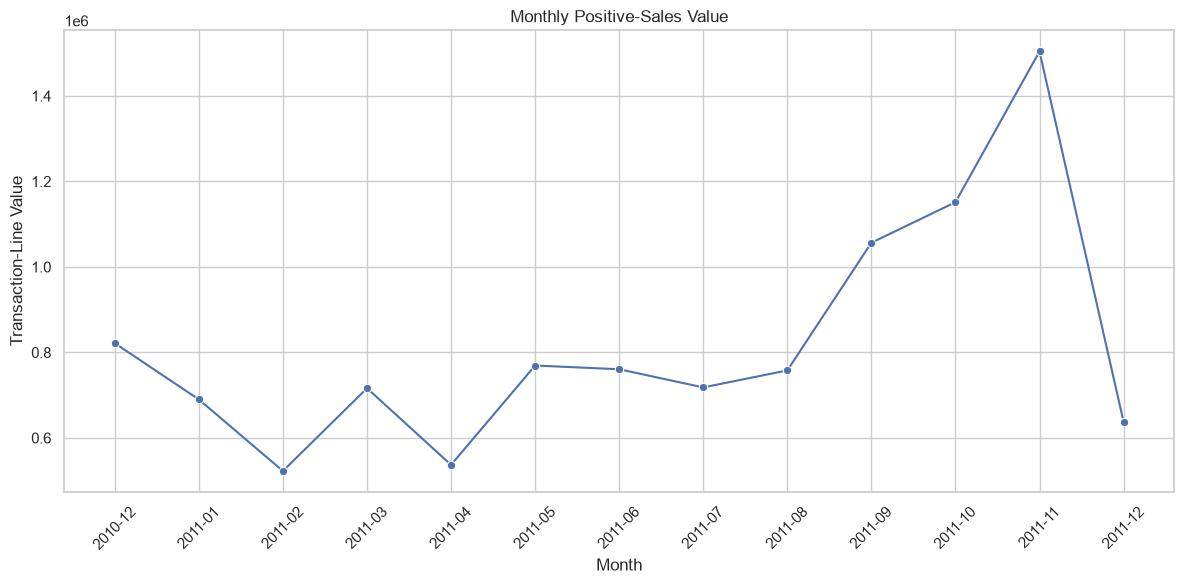


3. TOP 10 PRODUCTS BY SALES VALUE
stockcode  sales_value  quantity_sold  transaction_lines                        description
      DOT    206248.77            706                706                     DOTCOM POSTAGE
    22423    174156.54          13851               2007           REGENCY CAKESTAND 3 TIER
    23843    168469.60          80995                  1        PAPER CRAFT , LITTLE BIRDIE
   85123A    104462.75          37641               2253 WHITE HANGING HEART T-LIGHT HOLDER
    47566     99445.23          18283               1699                      PARTY BUNTING
   85099B     94159.81          48371               2109            JUMBO BAG RED RETROSPOT
    23166     81700.92          78033                250     MEDIUM CERAMIC TOP STORAGE JAR
     POST     78101.88           3150               1126                            POSTAGE
        M     77750.27           6984                316                             Manual
    23084     66870.03          30739        

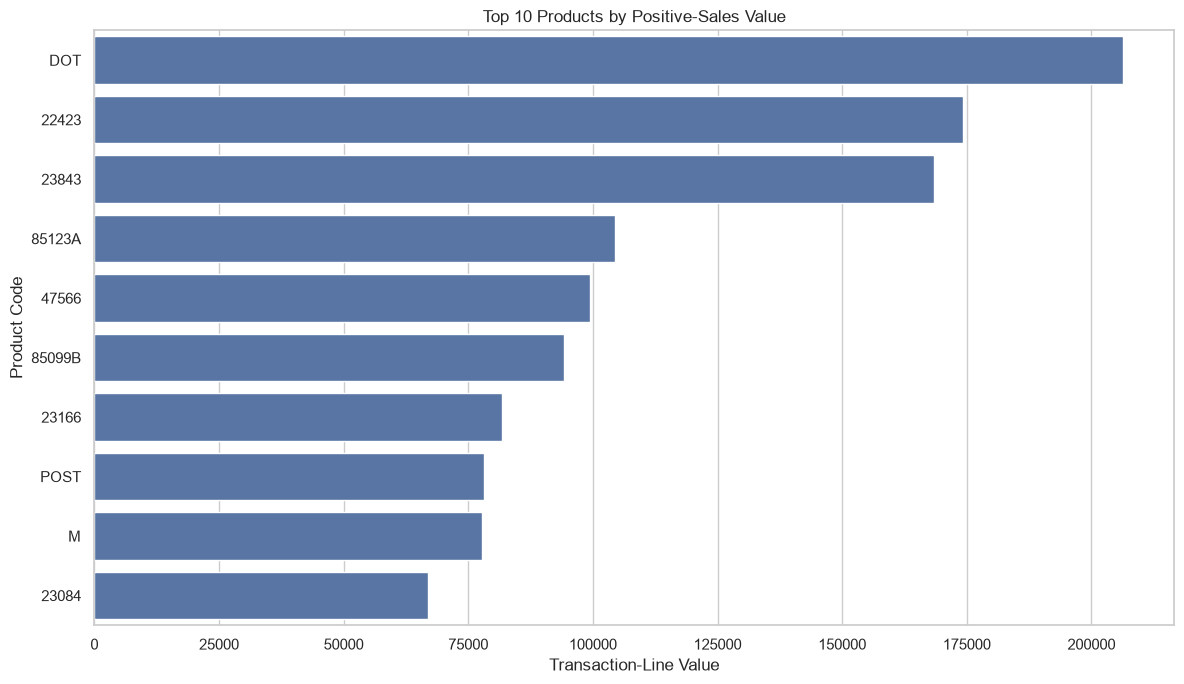


4. TOP 10 COUNTRIES BY SALES VALUE
       country  sales_value  quantity_sold  transaction_lines  invoices
United Kingdom  9001744.094        4646906             479985     18019
   Netherlands   285446.340         200361               2359        94
          EIRE   283140.520         147007               7879       288
       Germany   228678.400         119154               9025       457
        France   209625.370         112060               8392       392
     Australia   138453.810          83891               1181        57
         Spain    61558.560          27933               2479        90
   Switzerland    57067.600          30617               1958        54
       Belgium    41196.340          23237               2031        98
        Sweden    38367.830          36078                450        36


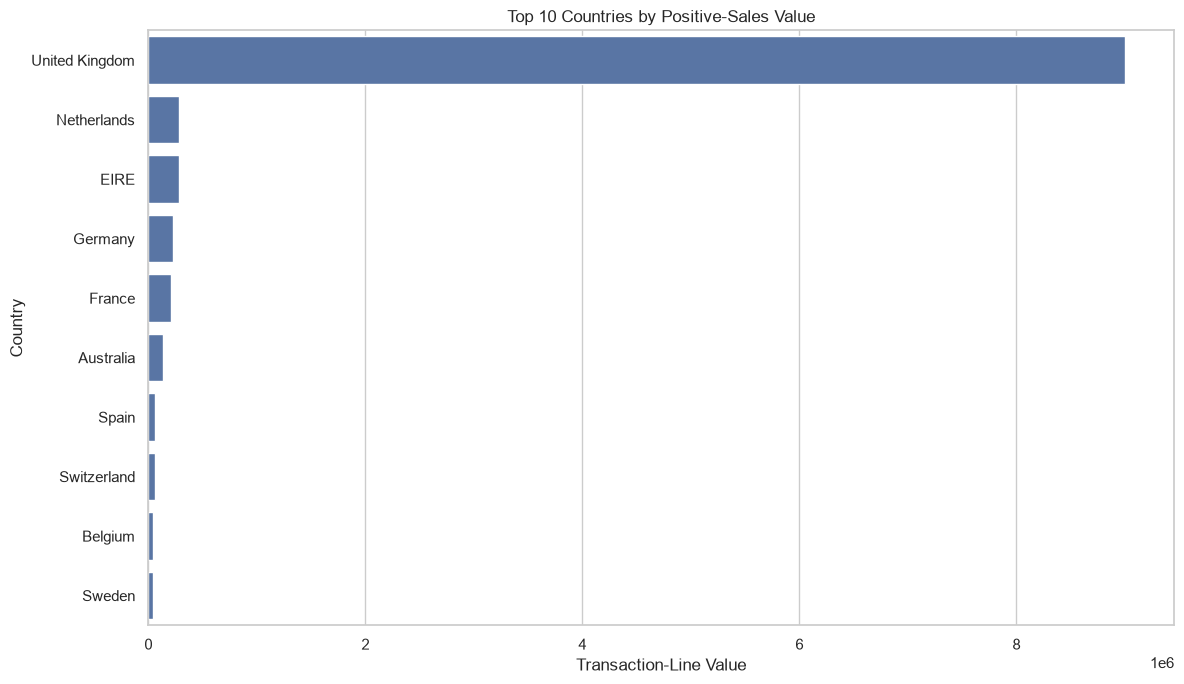


5. TOP 10 PRODUCTS BY QUANTITY SOLD
stockcode  quantity_sold  sales_value
    23843          80995    168469.60
    23166          78033     81700.92
    22197          56898     51334.47
    84077          54951     13814.01
   85099B          48371     94159.81
   85123A          37641    104462.75
    21212          36396     21246.45
    84879          36362     58927.62
    23084          30739     66870.03
    22492          26633     16937.82


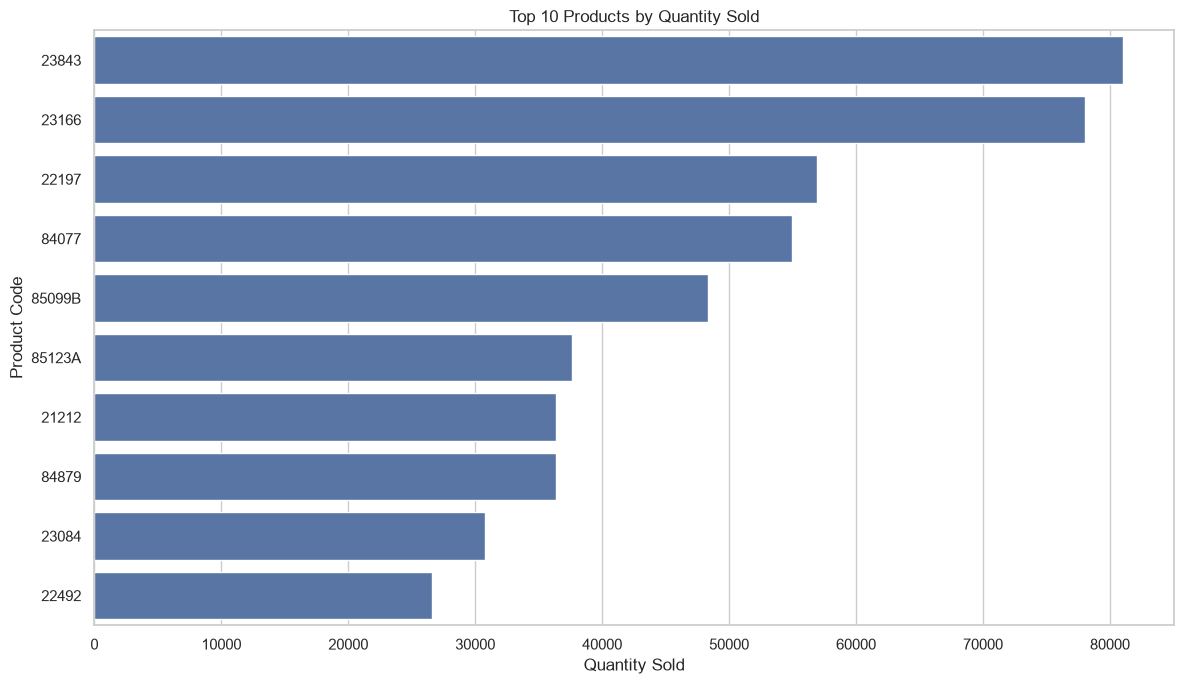


6. TRANSACTION TYPE ANALYSIS
    transaction_type  record_count  invoice_count  total_quantity  record_percentage
Cancellation Invoice          9251           3836         -275560               1.72
   Negative Quantity          1336           1336         -206957               0.25
   Positive Quantity        526054          20728         5645019              98.03


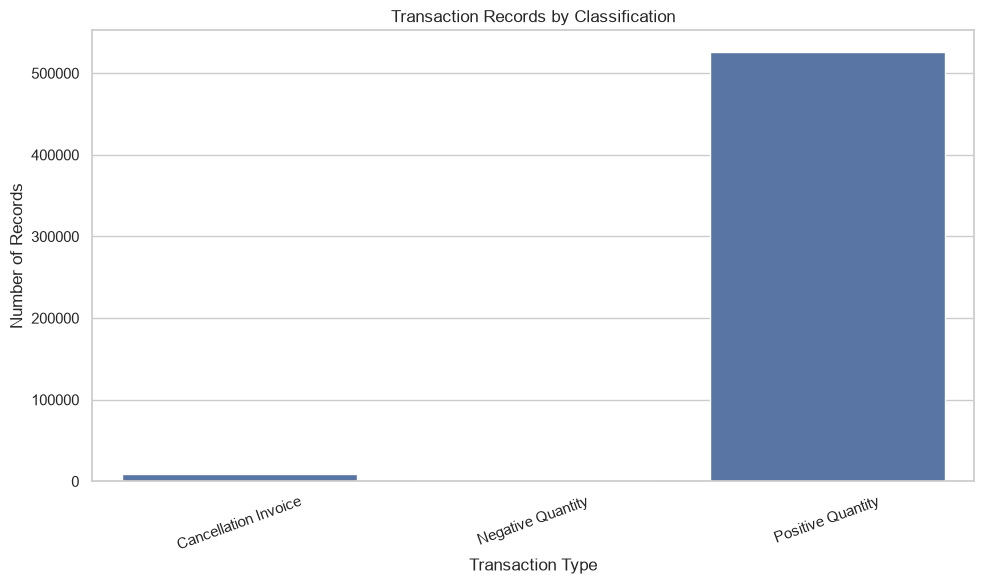


7. TOP 10 COUNTRIES BY INVOICE COUNT
       country  invoice_count  transaction_lines
United Kingdom          23494             490300
       Germany            603               9480
        France            461               8541
          EIRE            360               8184
       Belgium            119               2069
         Spain            105               2528
   Netherlands            101               2371
   Switzerland             74               1994
      Portugal             71               1510
     Australia             69               1258

8. KEY ANALYTICAL METRICS
                                 Metric       Value
  Positive-sales transaction-line value 10642110.80
                 Positive quantity sold  5572420.00
Invoices with qualifying positive sales    19960.00
       Average qualifying invoice value      533.17
        Unique products in cleaned data     4070.00
       Unique countries in cleaned data       38.00

9. OUTPUT FILES
Monthly sales: 

In [15]:
# ============================================================
# RETAIL CUSTOMER INTELLIGENCE
# STEP 8: EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

# Use the cleaned dataset created in Step 7.
# df_clean should already exist in the notebook.

eda_df = df_clean.copy()

# Separate transaction types for analysis.
# This is a reporting classification, not a claim that every
# negative quantity is a confirmed return.

eda_df["transaction_type"] = np.select(
    [
        eda_df["is_cancellation"],
        eda_df["quantity"] < 0,
        eda_df["quantity"] > 0
    ],
    [
        "Cancellation Invoice",
        "Negative Quantity",
        "Positive Quantity"
    ],
    default="Other"
)

# Create an output directory for charts.
figure_dir = Path("../reports/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("RETAIL CUSTOMER INTELLIGENCE - EXPLORATORY DATA ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 2. DEFINE ANALYTICAL MEASURES
# ------------------------------------------------------------

# Line value is Quantity * UnitPrice.
# These figures are transaction-line values, not accounting profit.
# We exclude cancellation invoices and non-positive quantities
# from the positive-sales analysis, but retain the original data.

positive_sales = eda_df[
    (~eda_df["is_cancellation"])
    & (eda_df["quantity"] > 0)
    & (eda_df["unitprice"] > 0)
].copy()

positive_sales["sales_value"] = (
    positive_sales["quantity"] * positive_sales["unitprice"]
)

print("\n1. ANALYTICAL DATA OVERVIEW")
print(f"Cleaned records: {len(eda_df):,}")
print(f"Positive-sales records: {len(positive_sales):,}")
print(f"Unique products: {eda_df['stockcode'].nunique():,}")
print(f"Unique countries: {eda_df['country'].nunique():,}")
print(
    "Identifiable customers:",
    f"{eda_df['customerid'].nunique():,}"
)

# ------------------------------------------------------------
# 3. MONTHLY SALES ANALYSIS
# ------------------------------------------------------------

print("\n2. MONTHLY SALES ANALYSIS")

positive_sales["month"] = (
    positive_sales["invoicedate"].dt.to_period("M").astype(str)
)

monthly_sales = (
    positive_sales.groupby("month", as_index=False)
    .agg(
        sales_value=("sales_value", "sum"),
        quantity_sold=("quantity", "sum"),
        transaction_lines=("invoiceno", "size"),
        invoices=("invoiceno", "nunique")
    )
)

monthly_sales["sales_value"] = monthly_sales["sales_value"].round(2)

print(monthly_sales.to_string(index=False))

monthly_sales.to_csv(
    "../data/processed/monthly_sales.csv",
    index=False
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_sales,
    x="month",
    y="sales_value",
    marker="o"
)

plt.title("Monthly Positive-Sales Value")
plt.xlabel("Month")
plt.ylabel("Transaction-Line Value")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    figure_dir / "monthly_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 4. TOP 10 PRODUCTS BY SALES VALUE
# ------------------------------------------------------------

print("\n3. TOP 10 PRODUCTS BY SALES VALUE")

product_sales = (
    positive_sales.groupby("stockcode", as_index=False)
    .agg(
        sales_value=("sales_value", "sum"),
        quantity_sold=("quantity", "sum"),
        transaction_lines=("invoiceno", "size")
    )
    .sort_values("sales_value", ascending=False)
)

# Add the most frequently observed description for each product.
product_descriptions = (
    positive_sales.dropna(subset=["description"])
    .groupby("stockcode")["description"]
    .agg(lambda values: values.mode().iloc[0] if not values.mode().empty else pd.NA)
    .rename("description")
)

product_sales = product_sales.merge(
    product_descriptions,
    on="stockcode",
    how="left"
)

top_products = product_sales.head(10)

print(top_products.to_string(index=False))

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_products,
    x="sales_value",
    y="stockcode"
)

plt.title("Top 10 Products by Positive-Sales Value")
plt.xlabel("Transaction-Line Value")
plt.ylabel("Product Code")
plt.tight_layout()

plt.savefig(
    figure_dir / "top_products.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. TOP 10 COUNTRIES BY SALES VALUE
# ------------------------------------------------------------

print("\n4. TOP 10 COUNTRIES BY SALES VALUE")

country_sales = (
    positive_sales.groupby("country", as_index=False)
    .agg(
        sales_value=("sales_value", "sum"),
        quantity_sold=("quantity", "sum"),
        transaction_lines=("invoiceno", "size"),
        invoices=("invoiceno", "nunique")
    )
    .sort_values("sales_value", ascending=False)
)

print(country_sales.head(10).to_string(index=False))

top_countries = country_sales.head(10)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_countries,
    x="sales_value",
    y="country"
)

plt.title("Top 10 Countries by Positive-Sales Value")
plt.xlabel("Transaction-Line Value")
plt.ylabel("Country")
plt.tight_layout()

plt.savefig(
    figure_dir / "top_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 6. TOP 10 PRODUCTS BY QUANTITY SOLD
# ------------------------------------------------------------

print("\n5. TOP 10 PRODUCTS BY QUANTITY SOLD")

top_quantity_products = (
    positive_sales.groupby("stockcode", as_index=False)
    .agg(
        quantity_sold=("quantity", "sum"),
        sales_value=("sales_value", "sum")
    )
    .sort_values("quantity_sold", ascending=False)
    .head(10)
)

print(top_quantity_products.to_string(index=False))

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_quantity_products,
    x="quantity_sold",
    y="stockcode"
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product Code")
plt.tight_layout()

plt.savefig(
    figure_dir / "top_products_by_quantity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 7. TRANSACTION TYPE ANALYSIS
# ------------------------------------------------------------

print("\n6. TRANSACTION TYPE ANALYSIS")

transaction_summary = (
    eda_df.groupby("transaction_type", as_index=False)
    .agg(
        record_count=("invoiceno", "size"),
        invoice_count=("invoiceno", "nunique"),
        total_quantity=("quantity", "sum")
    )
)

transaction_summary["record_percentage"] = (
    transaction_summary["record_count"]
    / len(eda_df) * 100
).round(2)

print(transaction_summary.to_string(index=False))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=transaction_summary,
    x="transaction_type",
    y="record_count"
)

plt.title("Transaction Records by Classification")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    figure_dir / "transaction_type_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 8. COUNTRY-LEVEL TRANSACTION ACTIVITY
# ------------------------------------------------------------

print("\n7. TOP 10 COUNTRIES BY INVOICE COUNT")

country_invoices = (
    eda_df.groupby("country", as_index=False)
    .agg(
        invoice_count=("invoiceno", "nunique"),
        transaction_lines=("invoiceno", "size")
    )
    .sort_values("invoice_count", ascending=False)
)

print(country_invoices.head(10).to_string(index=False))

# ------------------------------------------------------------
# 9. SUMMARY OF KEY METRICS
# ------------------------------------------------------------

print("\n8. KEY ANALYTICAL METRICS")

total_positive_sales_value = positive_sales["sales_value"].sum()

total_positive_quantity = positive_sales["quantity"].sum()

unique_positive_sales_invoices = (
    positive_sales["invoiceno"].nunique()
)

average_positive_invoice_value = (
    positive_sales.groupby("invoiceno")["sales_value"]
    .sum()
    .mean()
)

key_metrics = pd.DataFrame({
    "Metric": [
        "Positive-sales transaction-line value",
        "Positive quantity sold",
        "Invoices with qualifying positive sales",
        "Average qualifying invoice value",
        "Unique products in cleaned data",
        "Unique countries in cleaned data"
    ],
    "Value": [
        round(total_positive_sales_value, 2),
        int(total_positive_quantity),
        unique_positive_sales_invoices,
        round(average_positive_invoice_value, 2),
        eda_df["stockcode"].nunique(),
        eda_df["country"].nunique()
    ]
})

print(key_metrics.to_string(index=False))

# ------------------------------------------------------------
# 10. SAVE ANALYTICAL TABLES
# ------------------------------------------------------------

monthly_sales.to_csv(
    "../data/processed/monthly_sales.csv",
    index=False
)

product_sales.to_csv(
    "../data/processed/product_sales.csv",
    index=False
)

country_sales.to_csv(
    "../data/processed/country_sales.csv",
    index=False
)

transaction_summary.to_csv(
    "../data/processed/transaction_summary.csv",
    index=False
)

print("\n9. OUTPUT FILES")
print("Monthly sales: data/processed/monthly_sales.csv")
print("Product analysis: data/processed/product_sales.csv")
print("Country analysis: data/processed/country_sales.csv")
print("Transaction summary: data/processed/transaction_summary.csv")
print("Charts: reports/figures/")

print("\nExploratory Data Analysis completed successfully!")

In [16]:
# ============================================================
# STEP 10: TRANSACTION CLASSIFICATION AND PRODUCT VALIDATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("=" * 70)
print("TRANSACTION CLASSIFICATION AND PRODUCT VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. CREATE MUTUALLY EXCLUSIVE TRANSACTION CATEGORIES
# ------------------------------------------------------------

analysis_df = df_clean.copy()

conditions = [
    analysis_df["is_cancellation"],
    analysis_df["quantity"] < 0,
    analysis_df["unitprice"] <= 0,
    analysis_df["quantity"] > 0
]

categories = [
    "Cancellation Invoice",
    "Negative Quantity - Non-cancellation",
    "Non-positive Price",
    "Positive Quantity"
]

analysis_df["transaction_category"] = np.select(
    conditions,
    categories,
    default="Other"
)

transaction_summary = (
    analysis_df.groupby("transaction_category", as_index=False)
    .agg(
        record_count=("invoiceno", "size"),
        invoice_count=("invoiceno", "nunique"),
        total_quantity=("quantity", "sum")
    )
    .sort_values("record_count", ascending=False)
)

transaction_summary["record_percentage"] = (
    transaction_summary["record_count"]
    / len(analysis_df) * 100
).round(2)

print("\n1. TRANSACTION CATEGORY SUMMARY")
print(transaction_summary.to_string(index=False))


# ------------------------------------------------------------
# 2. IDENTIFY SPECIAL PRODUCT CODES
# ------------------------------------------------------------

print("\n2. SPECIAL PRODUCT CODE ANALYSIS")

special_keywords = (
    "POSTAGE",
    "DOTCOM POSTAGE",
    "MANUAL",
    "CARRIAGE",
    "BANK CHARGES"
)

description = (
    analysis_df["description"]
    .fillna("")
    .str.upper()
)

special_mask = description.str.contains(
    "|".join(special_keywords),
    regex=True
)

special_records = analysis_df[special_mask].copy()

print(f"Records matching special descriptions: {len(special_records):,}")
print(
    "Distinct special product codes:",
    special_records["stockcode"].nunique()
)

special_product_summary = (
    special_records.groupby(
        ["stockcode", "description"],
        dropna=False,
        as_index=False
    )
    .agg(
        record_count=("invoiceno", "size"),
        quantity=("quantity", "sum"),
        line_value=("line_value", "sum")
    )
    .sort_values("line_value", ascending=False)
)

print("\nTop special product codes:")
print(special_product_summary.head(15).to_string(index=False))


# ------------------------------------------------------------
# 3. INVESTIGATE UNUSUALLY LARGE QUANTITIES
# ------------------------------------------------------------

print("\n3. LARGE POSITIVE QUANTITY TRANSACTIONS")

large_quantity_records = (
    analysis_df[
        (analysis_df["quantity"] > 0)
        & (~analysis_df["is_cancellation"])
    ]
    .sort_values("quantity", ascending=False)
    .head(10)
)

columns_to_display = [
    "invoiceno",
    "stockcode",
    "description",
    "quantity",
    "unitprice",
    "line_value",
    "country"
]

print(large_quantity_records[columns_to_display].to_string(index=False))


# ------------------------------------------------------------
# 4. COMPARE SALES INCLUDING AND EXCLUDING SPECIAL ITEMS
# ------------------------------------------------------------

print("\n4. SALES VALUE COMPARISON")

# Base definition:
# Positive quantities, positive prices, non-cancellation invoices.

base_sales = analysis_df[
    (~analysis_df["is_cancellation"])
    & (analysis_df["quantity"] > 0)
    & (analysis_df["unitprice"] > 0)
].copy()

base_sales["sales_value"] = (
    base_sales["quantity"] * base_sales["unitprice"]
)

base_total = base_sales["sales_value"].sum()

# Sensitivity analysis:
# Exclude descriptions matching the special-item keywords.
# This is a proxy, not a complete product classification.

regular_sales = base_sales[
    ~base_sales["description"]
    .fillna("")
    .str.upper()
    .str.contains("|".join(special_keywords), regex=True)
].copy()

regular_total = regular_sales["sales_value"].sum()

sales_comparison = pd.DataFrame({
    "Scenario": [
        "Positive-sales records including special descriptions",
        "Positive-sales records excluding matched special descriptions"
    ],
    "Record_Count": [
        len(base_sales),
        len(regular_sales)
    ],
    "Sales_Value": [
        round(base_total, 2),
        round(regular_total, 2)
    ]
})

print(sales_comparison.to_string(index=False))


# ------------------------------------------------------------
# 5. CREATE A REVISED MONTHLY SALES TABLE
# ------------------------------------------------------------

base_sales["month"] = (
    base_sales["invoicedate"].dt.to_period("M").astype(str)
)

monthly_sales = (
    base_sales.groupby("month", as_index=False)
    .agg(
        sales_value=("sales_value", "sum"),
        quantity_sold=("quantity", "sum"),
        invoice_count=("invoiceno", "nunique")
    )
)

print("\n5. MONTHLY SALES TABLE")
print(monthly_sales.to_string(index=False))


# ------------------------------------------------------------
# 6. SAVE RESULTS
# ------------------------------------------------------------

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

transaction_summary.to_csv(
    output_dir / "transaction_classification.csv",
    index=False
)

special_product_summary.to_csv(
    output_dir / "special_product_analysis.csv",
    index=False
)

sales_comparison.to_csv(
    output_dir / "sales_sensitivity_analysis.csv",
    index=False
)

monthly_sales.to_csv(
    output_dir / "monthly_sales.csv",
    index=False
)

print("\n6. OUTPUT FILES")
print("transaction_classification.csv")
print("special_product_analysis.csv")
print("sales_sensitivity_analysis.csv")
print("monthly_sales.csv")

print("\nTransaction analysis completed successfully!")

TRANSACTION CLASSIFICATION AND PRODUCT VALIDATION

1. TRANSACTION CATEGORY SUMMARY
                transaction_category  record_count  invoice_count  total_quantity  record_percentage
                   Positive Quantity        524878          19960         5572420              97.81
                Cancellation Invoice          9251           3836         -275560               1.72
Negative Quantity - Non-cancellation          1336           1336         -206957               0.25
                  Non-positive Price          1176            821           72599               0.22

2. SPECIAL PRODUCT CODE ANALYSIS
Records matching special descriptions: 2,886
Distinct special product codes: 9

Top special product codes:
   stockcode                  description  record_count  quantity  line_value
         DOT               DOTCOM POSTAGE           709       707  206245.480
        POST                      POSTAGE          1252      3003   66230.640
          C2                     CARR

RFM CUSTOMER ANALYSIS AND SEGMENTATION

1. RFM DATA PREPARATION
Qualifying transaction lines: 392,692
Unique customers: 4,338
Unique invoices: 18,532
RFM reference date: 2011-12-10

2. RFM SUMMARY
       recency  frequency   monetary
count  4338.00    4338.00    4338.00
mean     93.06       4.27    2048.69
std     100.01       7.70    8985.23
min       1.00       1.00       3.75
25%      18.00       1.00     306.48
50%      51.00       2.00     668.57
75%     142.75       5.00    1660.60
max     374.00     209.00  280206.02

3. CUSTOMER SEGMENT DISTRIBUTION
                    segment  customer_count  average_recency  average_frequency  average_monetary  total_monetary  customer_percentage
       Potentially Inactive            1072           217.47               1.10            488.07       523208.53                24.71
           High-Value Loyal             941            12.98              11.21           6101.93      5741913.58                21.69
         Frequent Customers    

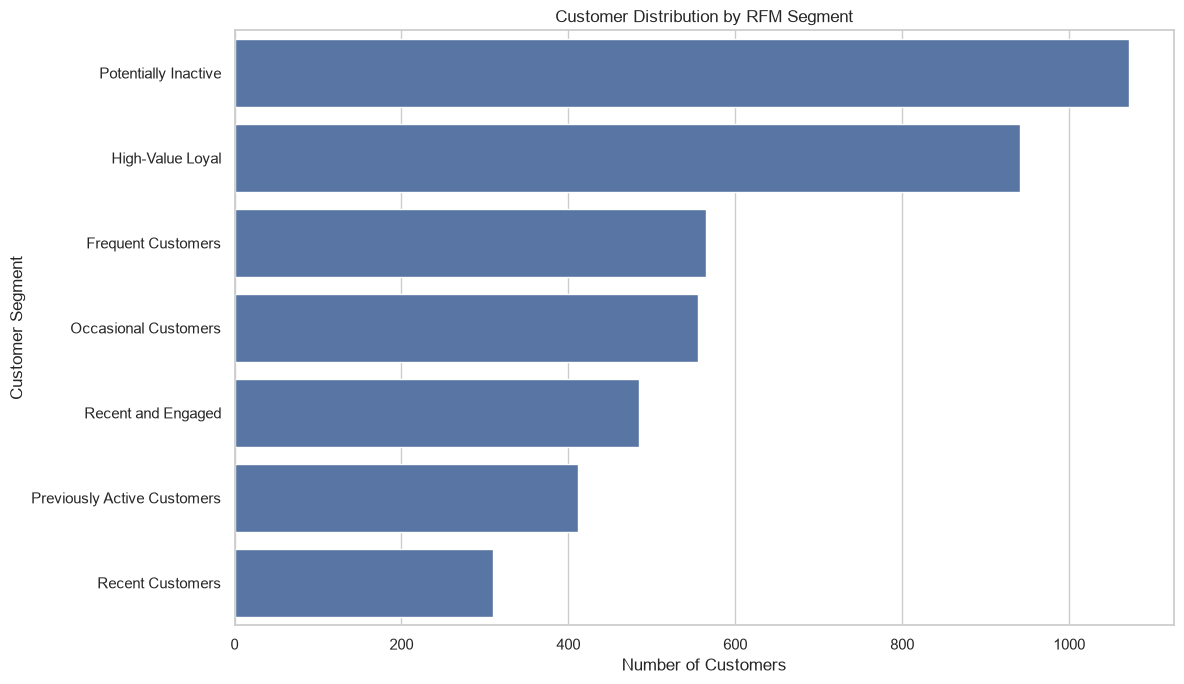

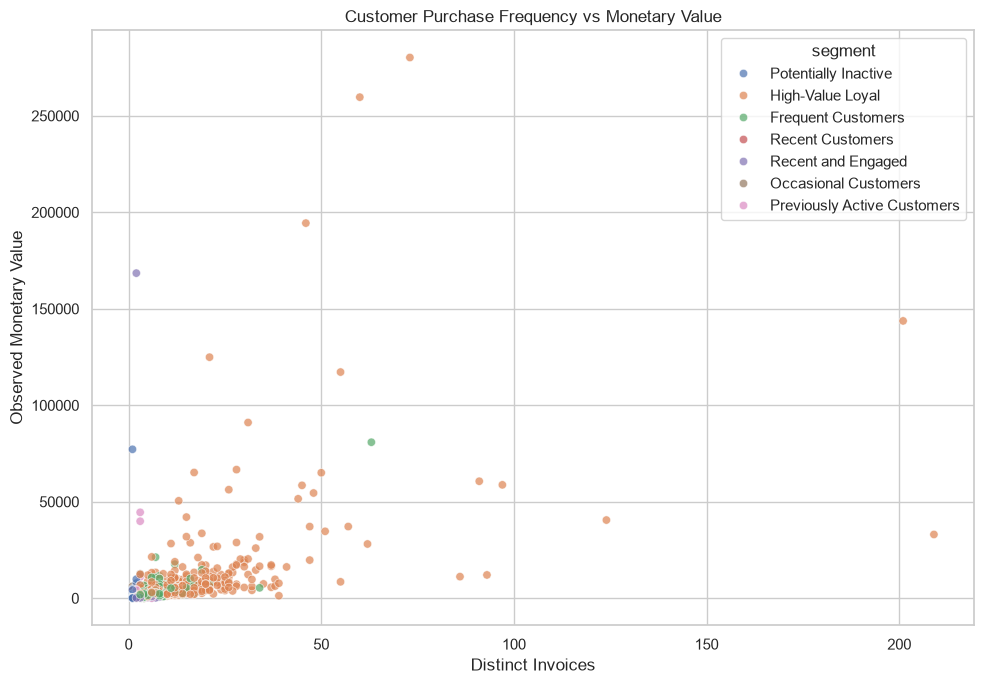


5. OUTPUT FILES
customer_features.csv
customer_segments.csv
customer_segment_summary.csv
customer_segments.png
customer_frequency_vs_monetary.png

RFM customer analysis completed successfully!


In [17]:
# ============================================================
# RETAIL CUSTOMER INTELLIGENCE
# STEP 11: RFM CUSTOMER ANALYSIS AND SEGMENTATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

print("=" * 70)
print("RFM CUSTOMER ANALYSIS AND SEGMENTATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. PREPARE CUSTOMER TRANSACTION DATA
# ------------------------------------------------------------

rfm_df = df_clean.copy()

# Include only transactions with identifiable customers.
# Exclude cancellation invoices and non-positive quantities/prices.

rfm_df = rfm_df[
    rfm_df["customerid"].notna()
    & (~rfm_df["is_cancellation"])
    & (rfm_df["quantity"] > 0)
    & (rfm_df["unitprice"] > 0)
].copy()

# Calculate transaction-line value.

rfm_df["line_value"] = (
    rfm_df["quantity"] * rfm_df["unitprice"]
)

# Remove rows with invalid values needed for RFM.

rfm_df = rfm_df.dropna(
    subset=["customerid", "invoiceno", "invoicedate", "line_value"]
)

print("\n1. RFM DATA PREPARATION")
print(f"Qualifying transaction lines: {len(rfm_df):,}")
print(f"Unique customers: {rfm_df['customerid'].nunique():,}")
print(f"Unique invoices: {rfm_df['invoiceno'].nunique():,}")


# ------------------------------------------------------------
# 2. DEFINE THE REFERENCE DATE
# ------------------------------------------------------------

reference_date = (
    rfm_df["invoicedate"].max().normalize()
    + pd.Timedelta(days=1)
)

print(f"RFM reference date: {reference_date.date()}")


# ------------------------------------------------------------
# 3. CALCULATE RFM METRICS
# ------------------------------------------------------------

rfm = (
    rfm_df.groupby("customerid")
    .agg(
        last_purchase=("invoicedate", "max"),
        frequency=("invoiceno", "nunique"),
        monetary=("line_value", "sum")
    )
    .reset_index()
)

rfm["recency"] = (
    reference_date - rfm["last_purchase"].dt.normalize()
).dt.days

# Arrange columns.

rfm = rfm[
    [
        "customerid",
        "recency",
        "frequency",
        "monetary",
        "last_purchase"
    ]
]

print("\n2. RFM SUMMARY")
print(rfm[["recency", "frequency", "monetary"]].describe().round(2))


# ------------------------------------------------------------
# 4. ASSIGN RFM SCORES
# ------------------------------------------------------------

# Recency: lower days since purchase means a better score.
# Frequency and Monetary: higher values mean better scores.
#
# rank(method="first") helps qcut assign scores when many
# customers have identical values.

def assign_quantile_score(series, higher_is_better=True):
    ranked = series.rank(method="first")

    scores = pd.qcut(
        ranked,
        q=5,
        labels=[1, 2, 3, 4, 5]
    ).astype(int)

    if not higher_is_better:
        scores = 6 - scores

    return scores


rfm["R_score"] = assign_quantile_score(
    rfm["recency"],
    higher_is_better=False
)

rfm["F_score"] = assign_quantile_score(
    rfm["frequency"],
    higher_is_better=True
)

rfm["M_score"] = assign_quantile_score(
    rfm["monetary"],
    higher_is_better=True
)

rfm["RFM_score"] = (
    rfm["R_score"].astype(str)
    + rfm["F_score"].astype(str)
    + rfm["M_score"].astype(str)
)


# ------------------------------------------------------------
# 5. CREATE INTERPRETABLE CUSTOMER SEGMENTS
# ------------------------------------------------------------

def classify_customer(row):

    r = row["R_score"]
    f = row["F_score"]
    m = row["M_score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "High-Value Loyal"

    elif r >= 4 and f >= 3:
        return "Recent and Engaged"

    elif f >= 4 and m >= 3:
        return "Frequent Customers"

    elif r >= 4 and f <= 2:
        return "Recent Customers"

    elif r <= 2 and f >= 3:
        return "Previously Active Customers"

    elif r <= 2 and f <= 2:
        return "Potentially Inactive"

    else:
        return "Occasional Customers"


rfm["segment"] = rfm.apply(
    classify_customer,
    axis=1
)

print("\n3. CUSTOMER SEGMENT DISTRIBUTION")

segment_summary = (
    rfm.groupby("segment", as_index=False)
    .agg(
        customer_count=("customerid", "nunique"),
        average_recency=("recency", "mean"),
        average_frequency=("frequency", "mean"),
        average_monetary=("monetary", "mean"),
        total_monetary=("monetary", "sum")
    )
    .sort_values("customer_count", ascending=False)
)

segment_summary["customer_percentage"] = (
    segment_summary["customer_count"]
    / rfm["customerid"].nunique() * 100
).round(2)

segment_summary[
    [
        "average_recency",
        "average_frequency",
        "average_monetary",
        "total_monetary"
    ]
] = segment_summary[
    [
        "average_recency",
        "average_frequency",
        "average_monetary",
        "total_monetary"
    ]
].round(2)

print(segment_summary.to_string(index=False))


# ------------------------------------------------------------
# 6. IDENTIFY TOP 10 CUSTOMERS BY MONETARY VALUE
# ------------------------------------------------------------

print("\n4. TOP 10 CUSTOMERS BY OBSERVED MONETARY VALUE")

top_customers = (
    rfm.sort_values("monetary", ascending=False)
    .head(10)
)

print(
    top_customers[
        [
            "customerid",
            "recency",
            "frequency",
            "monetary",
            "segment"
        ]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 7. VISUALIZE CUSTOMER SEGMENTS
# ------------------------------------------------------------

plt.figure(figsize=(12, 7))

sns.barplot(
    data=segment_summary,
    x="customer_count",
    y="segment"
)

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")
plt.tight_layout()

figure_dir = Path("../reports/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_dir / "customer_segments.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 8. VISUALIZE CUSTOMER FREQUENCY AND MONETARY VALUE
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=rfm,
    x="frequency",
    y="monetary",
    hue="segment",
    alpha=0.7
)

plt.title("Customer Purchase Frequency vs Monetary Value")
plt.xlabel("Distinct Invoices")
plt.ylabel("Observed Monetary Value")
plt.tight_layout()

plt.savefig(
    figure_dir / "customer_frequency_vs_monetary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 9. SAVE RFM OUTPUTS
# ------------------------------------------------------------

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

rfm.to_csv(
    output_dir / "customer_features.csv",
    index=False
)

rfm.to_csv(
    output_dir / "customer_segments.csv",
    index=False
)

segment_summary.to_csv(
    output_dir / "customer_segment_summary.csv",
    index=False
)

print("\n5. OUTPUT FILES")
print("customer_features.csv")
print("customer_segments.csv")
print("customer_segment_summary.csv")
print("customer_segments.png")
print("customer_frequency_vs_monetary.png")

print("\nRFM customer analysis completed successfully!")

In [18]:
# ============================================================
# RETAIL CUSTOMER INTELLIGENCE
# STEP 12: RFM VALIDATION AND BUSINESS INSIGHTS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 70)
print("RFM VALIDATION AND BUSINESS INSIGHTS")
print("=" * 70)

# ------------------------------------------------------------
# 1. VALIDATE CUSTOMER-LEVEL DATA
# ------------------------------------------------------------

print("\n1. CUSTOMER DATA VALIDATION")

print(f"Total customer records: {len(rfm):,}")
print(f"Unique customer IDs: {rfm['customerid'].nunique():,}")
print(f"Duplicate customer IDs: {rfm['customerid'].duplicated().sum():,}")

print(f"Missing recency: {rfm['recency'].isna().sum():,}")
print(f"Missing frequency: {rfm['frequency'].isna().sum():,}")
print(f"Missing monetary: {rfm['monetary'].isna().sum():,}")

print(f"Customers with recency below zero: {(rfm['recency'] < 0).sum():,}")
print(f"Customers with frequency below one: {(rfm['frequency'] < 1).sum():,}")
print(f"Customers with monetary value at or below zero: {(rfm['monetary'] <= 0).sum():,}")

assert rfm["customerid"].is_unique, "Duplicate customer IDs found."
assert rfm["recency"].notna().all(), "Missing recency values found."
assert rfm["frequency"].notna().all(), "Missing frequency values found."
assert rfm["monetary"].notna().all(), "Missing monetary values found."
assert (rfm["recency"] >= 0).all(), "Negative recency values found."
assert (rfm["frequency"] >= 1).all(), "Invalid frequency values found."
assert (rfm["monetary"] > 0).all(), "Non-positive monetary values found."

print("\nCustomer-level validation passed.")


# ------------------------------------------------------------
# 2. VALIDATE RFM SCORES
# ------------------------------------------------------------

print("\n2. RFM SCORE VALIDATION")

score_columns = ["R_score", "F_score", "M_score"]

for column in score_columns:
    print(f"\n{column} distribution:")
    print(rfm[column].value_counts().sort_index().to_string())

    assert rfm[column].between(1, 5).all(), (
        f"{column} contains scores outside the range 1–5."
    )

print("\nRFM score validation passed.")


# ------------------------------------------------------------
# 3. VALIDATE CUSTOMER SEGMENTS
# ------------------------------------------------------------

print("\n3. SEGMENT VALIDATION")

print(f"Customers in RFM table: {rfm['customerid'].nunique():,}")
print(f"Customers in segment summary: {segment_summary['customer_count'].sum():,}")

print("\nCustomer counts by segment:")
print(
    segment_summary[
        ["segment", "customer_count", "customer_percentage"]
    ].to_string(index=False)
)

assert rfm["segment"].notna().all(), "Some customers have no segment."
assert segment_summary["customer_count"].sum() == len(rfm), (
    "Segment totals do not match the RFM customer count."
)

percentage_total = segment_summary["customer_percentage"].sum()
print(f"\nTotal customer percentage: {percentage_total:.2f}%")

assert np.isclose(percentage_total, 100.0, atol=0.1), (
    "Customer percentages do not add up to approximately 100%."
)

print("Segment validation passed.")


# ------------------------------------------------------------
# 4. IDENTIFY HIGH-VALUE CUSTOMERS
# ------------------------------------------------------------

print("\n4. HIGH-VALUE CUSTOMER ANALYSIS")

high_value = rfm[rfm["segment"] == "High-Value Loyal"].copy()

print(f"High-Value Loyal customers: {len(high_value):,}")

if not high_value.empty:
    print(
        f"Average monetary value: "
        f"{high_value['monetary'].mean():,.2f}"
    )
    print(
        f"Total monetary value: "
        f"{high_value['monetary'].sum():,.2f}"
    )
    print(
        f"Average purchase frequency: "
        f"{high_value['frequency'].mean():.2f}"
    )
    print(
        f"Average recency: "
        f"{high_value['recency'].mean():.2f} days"
    )


# ------------------------------------------------------------
# 5. IDENTIFY CUSTOMERS WHO MAY NEED RE-ENGAGEMENT
# ------------------------------------------------------------

print("\n5. POTENTIALLY INACTIVE CUSTOMER ANALYSIS")

inactive = rfm[rfm["segment"] == "Potentially Inactive"].copy()

print(f"Potentially Inactive customers: {len(inactive):,}")

if not inactive.empty:
    print(
        f"Average recency: "
        f"{inactive['recency'].mean():.2f} days"
    )
    print(
        f"Average frequency: "
        f"{inactive['frequency'].mean():.2f} invoices"
    )
    print(
        f"Average monetary value: "
        f"{inactive['monetary'].mean():,.2f}"
    )
    print(
        f"Total monetary value: "
        f"{inactive['monetary'].sum():,.2f}"
    )


# ------------------------------------------------------------
# 6. CREATE A BUSINESS INSIGHTS TABLE
# ------------------------------------------------------------

business_insights = segment_summary.copy()

business_insights["recommended_action"] = business_insights["segment"].map({
    "High-Value Loyal":
        "Retain through loyalty benefits and personalised offers",

    "Frequent Customers":
        "Encourage repeat purchases and cross-selling",

    "Recent and Engaged":
        "Nurture engagement and encourage another purchase",

    "Recent Customers":
        "Encourage a second purchase",

    "Potentially Inactive":
        "Consider targeted re-engagement campaigns",

    "Previously Active Customers":
        "Investigate reduced activity and consider win-back offers",

    "Occasional Customers":
        "Encourage more frequent purchases"
})

print("\n6. BUSINESS ACTION RECOMMENDATIONS")

print(
    business_insights[
        [
            "segment",
            "customer_count",
            "customer_percentage",
            "average_recency",
            "average_frequency",
            "average_monetary",
            "recommended_action"
        ]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 7. SAVE VALIDATION OUTPUTS
# ------------------------------------------------------------

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

business_insights.to_csv(
    output_dir / "customer_business_insights.csv",
    index=False
)

high_value.sort_values(
    "monetary", ascending=False
).to_csv(
    output_dir / "high_value_customers.csv",
    index=False
)

inactive.sort_values(
    "recency", ascending=False
).to_csv(
    output_dir / "potentially_inactive_customers.csv",
    index=False
)

print("\n7. OUTPUT FILES")
print("customer_business_insights.csv")
print("high_value_customers.csv")
print("potentially_inactive_customers.csv")

print("\nRFM validation and business insights completed!")

RFM VALIDATION AND BUSINESS INSIGHTS

1. CUSTOMER DATA VALIDATION
Total customer records: 4,338
Unique customer IDs: 4,338
Duplicate customer IDs: 0
Missing recency: 0
Missing frequency: 0
Missing monetary: 0
Customers with recency below zero: 0
Customers with frequency below one: 0
Customers with monetary value at or below zero: 0

Customer-level validation passed.

2. RFM SCORE VALIDATION

R_score distribution:
R_score
1    868
2    867
3    868
4    867
5    868

F_score distribution:
F_score
1    868
2    867
3    868
4    867
5    868

M_score distribution:
M_score
1    868
2    867
3    868
4    867
5    868

RFM score validation passed.

3. SEGMENT VALIDATION
Customers in RFM table: 4,338
Customers in segment summary: 4,338

Customer counts by segment:
                    segment  customer_count  customer_percentage
       Potentially Inactive            1072                24.71
           High-Value Loyal             941                21.69
         Frequent Customers        

In [19]:
# ============================================================
# RETAIL CUSTOMER INTELLIGENCE
# STEP 12: RFM VALIDATION AND BUSINESS INSIGHTS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 70)
print("RFM VALIDATION AND BUSINESS INSIGHTS")
print("=" * 70)

# ------------------------------------------------------------
# 1. VALIDATE CUSTOMER-LEVEL DATA
# ------------------------------------------------------------

print("\n1. CUSTOMER DATA VALIDATION")

print(f"Total customer records: {len(rfm):,}")
print(f"Unique customer IDs: {rfm['customerid'].nunique():,}")
print(f"Duplicate customer IDs: {rfm['customerid'].duplicated().sum():,}")

print(f"Missing recency: {rfm['recency'].isna().sum():,}")
print(f"Missing frequency: {rfm['frequency'].isna().sum():,}")
print(f"Missing monetary: {rfm['monetary'].isna().sum():,}")

print(f"Customers with recency below zero: {(rfm['recency'] < 0).sum():,}")
print(f"Customers with frequency below one: {(rfm['frequency'] < 1).sum():,}")
print(f"Customers with monetary value at or below zero: {(rfm['monetary'] <= 0).sum():,}")

assert rfm["customerid"].is_unique, "Duplicate customer IDs found."
assert rfm["recency"].notna().all(), "Missing recency values found."
assert rfm["frequency"].notna().all(), "Missing frequency values found."
assert rfm["monetary"].notna().all(), "Missing monetary values found."
assert (rfm["recency"] >= 0).all(), "Negative recency values found."
assert (rfm["frequency"] >= 1).all(), "Invalid frequency values found."
assert (rfm["monetary"] > 0).all(), "Non-positive monetary values found."

print("\nCustomer-level validation passed.")


# ------------------------------------------------------------
# 2. VALIDATE RFM SCORES
# ------------------------------------------------------------

print("\n2. RFM SCORE VALIDATION")

score_columns = ["R_score", "F_score", "M_score"]

for column in score_columns:
    print(f"\n{column} distribution:")
    print(rfm[column].value_counts().sort_index().to_string())

    assert rfm[column].between(1, 5).all(), (
        f"{column} contains scores outside the range 1–5."
    )

print("\nRFM score validation passed.")


# ------------------------------------------------------------
# 3. VALIDATE CUSTOMER SEGMENTS
# ------------------------------------------------------------

print("\n3. SEGMENT VALIDATION")

print(f"Customers in RFM table: {rfm['customerid'].nunique():,}")
print(f"Customers in segment summary: {segment_summary['customer_count'].sum():,}")

print("\nCustomer counts by segment:")
print(
    segment_summary[
        ["segment", "customer_count", "customer_percentage"]
    ].to_string(index=False)
)

assert rfm["segment"].notna().all(), "Some customers have no segment."
assert segment_summary["customer_count"].sum() == len(rfm), (
    "Segment totals do not match the RFM customer count."
)

percentage_total = segment_summary["customer_percentage"].sum()
print(f"\nTotal customer percentage: {percentage_total:.2f}%")

assert np.isclose(percentage_total, 100.0, atol=0.1), (
    "Customer percentages do not add up to approximately 100%."
)

print("Segment validation passed.")


# ------------------------------------------------------------
# 4. IDENTIFY HIGH-VALUE CUSTOMERS
# ------------------------------------------------------------

print("\n4. HIGH-VALUE CUSTOMER ANALYSIS")

high_value = rfm[rfm["segment"] == "High-Value Loyal"].copy()

print(f"High-Value Loyal customers: {len(high_value):,}")

if not high_value.empty:
    print(
        f"Average monetary value: "
        f"{high_value['monetary'].mean():,.2f}"
    )
    print(
        f"Total monetary value: "
        f"{high_value['monetary'].sum():,.2f}"
    )
    print(
        f"Average purchase frequency: "
        f"{high_value['frequency'].mean():.2f}"
    )
    print(
        f"Average recency: "
        f"{high_value['recency'].mean():.2f} days"
    )


# ------------------------------------------------------------
# 5. IDENTIFY CUSTOMERS WHO MAY NEED RE-ENGAGEMENT
# ------------------------------------------------------------

print("\n5. POTENTIALLY INACTIVE CUSTOMER ANALYSIS")

inactive = rfm[rfm["segment"] == "Potentially Inactive"].copy()

print(f"Potentially Inactive customers: {len(inactive):,}")

if not inactive.empty:
    print(
        f"Average recency: "
        f"{inactive['recency'].mean():.2f} days"
    )
    print(
        f"Average frequency: "
        f"{inactive['frequency'].mean():.2f} invoices"
    )
    print(
        f"Average monetary value: "
        f"{inactive['monetary'].mean():,.2f}"
    )
    print(
        f"Total monetary value: "
        f"{inactive['monetary'].sum():,.2f}"
    )


# ------------------------------------------------------------
# 6. CREATE A BUSINESS INSIGHTS TABLE
# ------------------------------------------------------------

business_insights = segment_summary.copy()

business_insights["recommended_action"] = business_insights["segment"].map({
    "High-Value Loyal":
        "Retain through loyalty benefits and personalised offers",

    "Frequent Customers":
        "Encourage repeat purchases and cross-selling",

    "Recent and Engaged":
        "Nurture engagement and encourage another purchase",

    "Recent Customers":
        "Encourage a second purchase",

    "Potentially Inactive":
        "Consider targeted re-engagement campaigns",

    "Previously Active Customers":
        "Investigate reduced activity and consider win-back offers",

    "Occasional Customers":
        "Encourage more frequent purchases"
})

print("\n6. BUSINESS ACTION RECOMMENDATIONS")

print(
    business_insights[
        [
            "segment",
            "customer_count",
            "customer_percentage",
            "average_recency",
            "average_frequency",
            "average_monetary",
            "recommended_action"
        ]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 7. SAVE VALIDATION OUTPUTS
# ------------------------------------------------------------

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

business_insights.to_csv(
    output_dir / "customer_business_insights.csv",
    index=False
)

high_value.sort_values(
    "monetary", ascending=False
).to_csv(
    output_dir / "high_value_customers.csv",
    index=False
)

inactive.sort_values(
    "recency", ascending=False
).to_csv(
    output_dir / "potentially_inactive_customers.csv",
    index=False
)

print("\n7. OUTPUT FILES")
print("customer_business_insights.csv")
print("high_value_customers.csv")
print("potentially_inactive_customers.csv")

print("\nRFM validation and business insights completed!")

RFM VALIDATION AND BUSINESS INSIGHTS

1. CUSTOMER DATA VALIDATION
Total customer records: 4,338
Unique customer IDs: 4,338
Duplicate customer IDs: 0
Missing recency: 0
Missing frequency: 0
Missing monetary: 0
Customers with recency below zero: 0
Customers with frequency below one: 0
Customers with monetary value at or below zero: 0

Customer-level validation passed.

2. RFM SCORE VALIDATION

R_score distribution:
R_score
1    868
2    867
3    868
4    867
5    868

F_score distribution:
F_score
1    868
2    867
3    868
4    867
5    868

M_score distribution:
M_score
1    868
2    867
3    868
4    867
5    868

RFM score validation passed.

3. SEGMENT VALIDATION
Customers in RFM table: 4,338
Customers in segment summary: 4,338

Customer counts by segment:
                    segment  customer_count  customer_percentage
       Potentially Inactive            1072                24.71
           High-Value Loyal             941                21.69
         Frequent Customers        

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load the previously saved cleaned dataset
df_clean = pd.read_csv(
    "../data/processed/cleaned_transactions.csv",
    low_memory=False
)

# Convert columns back to their appropriate data types
df_clean["invoicedate"] = pd.to_datetime(
    df_clean["invoicedate"],
    errors="coerce"
)

df_clean["quantity"] = pd.to_numeric(
    df_clean["quantity"],
    errors="coerce"
)

df_clean["unitprice"] = pd.to_numeric(
    df_clean["unitprice"],
    errors="coerce"
)

# Display the results
print("Cleaned dataset loaded successfully!")
print(f"Rows: {len(df_clean):,}")
print(f"Columns: {len(df_clean.columns)}")
print(df_clean.head())

Cleaned dataset loaded successfully!
Rows: 536,641
Columns: 14
  invoiceno stockcode                          description  quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          invoicedate  unitprice  customerid         country  is_cancellation  \
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom            False   
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom            False   
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom            False   
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom            False   
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom            False   

   is_negative_qu

MARKET BASKET ANALYSIS

1. TRANSACTION DATA PREPARATION
Qualifying transaction lines: 392,692
Unique invoices: 18,532
Unique products: 3,665

2. INVOICE BASKET MATRIX
Number of invoice baskets: 18,532
Number of product columns: 3,665
Matrix memory usage: 519.16 MB

3. PRODUCT FILTERING
Minimum support threshold: 0.500%
Products before filtering: 3,665
Products selected for analysis: 100

4. FREQUENT ITEMSETS
Frequent itemsets discovered: 1,547
                                                                                          products  support  item_count
GREEN REGENCY TEACUP AND SAUCER + PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER 0.021045           3
      REGENCY CAKESTAND 3 TIER + GREEN REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER 0.016836           3
                       LUNCH BAG RED RETROSPOT + LUNCH BAG  BLACK SKULL. + LUNCH BAG PINK POLKADOT 0.016620           3
                         LUNCH BAG RED RETROSPOT + LUNCH BAG  BLACK SKUL

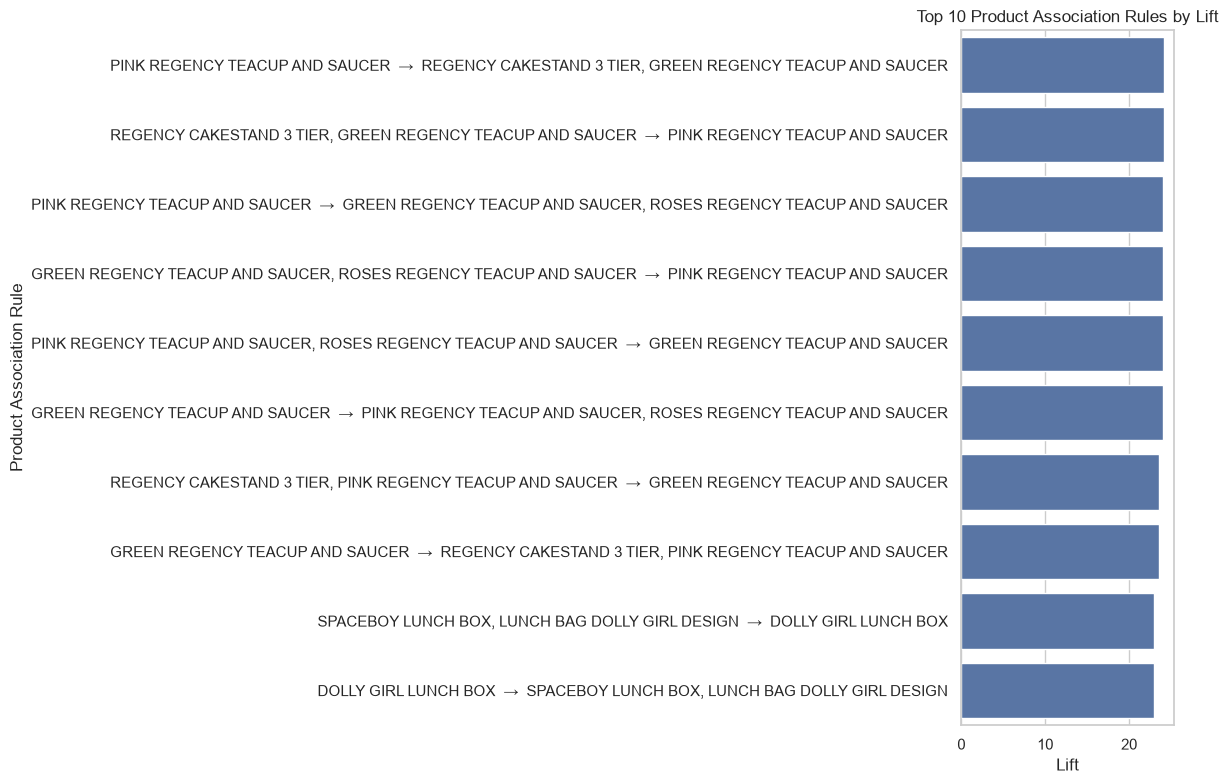


7. OUTPUT FILES
frequent_itemsets.csv
market_basket_rules.csv
market_basket_top_rules.png

Market Basket Analysis completed!


In [6]:
# ============================================================
# RETAIL CUSTOMER INTELLIGENCE
# STEP 13: MARKET BASKET ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from mlxtend.frequent_patterns import apriori, association_rules

sns.set_theme(style="whitegrid")

print("=" * 70)
print("MARKET BASKET ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 1. PREPARE TRANSACTION DATA
# ------------------------------------------------------------

basket_df = df_clean.copy()

basket_df = basket_df[
    basket_df["customerid"].notna()
    & (~basket_df["is_cancellation"])
    & (basket_df["quantity"] > 0)
    & (basket_df["unitprice"] > 0)
].copy()

basket_df = basket_df.dropna(
    subset=["invoiceno", "stockcode", "description"]
)

# Exclude blank product codes and descriptions
basket_df["stockcode"] = basket_df["stockcode"].astype(str).str.strip()
basket_df["description"] = basket_df["description"].astype(str).str.strip()

basket_df = basket_df[
    (basket_df["stockcode"] != "")
    & (basket_df["description"] != "")
].copy()

print("\n1. TRANSACTION DATA PREPARATION")
print(f"Qualifying transaction lines: {len(basket_df):,}")
print(f"Unique invoices: {basket_df['invoiceno'].nunique():,}")
print(f"Unique products: {basket_df['stockcode'].nunique():,}")

# ------------------------------------------------------------
# 2. CREATE INVOICE-PRODUCT BASKETS
# ------------------------------------------------------------

# Each invoice is a basket.
# A product appears only once per invoice, even if the quantity
# purchased is greater than one.

invoice_products = basket_df[
    ["invoiceno", "stockcode", "description"]
].drop_duplicates(
    subset=["invoiceno", "stockcode"]
)

# Keep the most common description for each product code.
product_descriptions = (
    basket_df.groupby("stockcode")["description"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else x.iloc[0])
    .to_dict()
)

# One-hot encode each invoice:
# 1 = product appears in the invoice
# 0 = product does not appear in the invoice

basket = pd.crosstab(
    invoice_products["invoiceno"],
    invoice_products["stockcode"]
).clip(upper=1)

print("\n2. INVOICE BASKET MATRIX")
print(f"Number of invoice baskets: {basket.shape[0]:,}")
print(f"Number of product columns: {basket.shape[1]:,}")
print(f"Matrix memory usage: {basket.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB")

# ------------------------------------------------------------
# 3. FILTER VERY RARE PRODUCTS
# ------------------------------------------------------------

# Keep products appearing in at least 0.5% of baskets.
# This threshold reduces the number of product combinations.
# We will also limit the analysis to the 100 most common products
# to keep computation practical.

minimum_support = 0.005

product_support = basket.mean().sort_values(ascending=False)

frequent_products = product_support[
    product_support >= minimum_support
].head(100).index

basket_reduced = basket[frequent_products].astype(bool)

print("\n3. PRODUCT FILTERING")
print(f"Minimum support threshold: {minimum_support:.3%}")
print(f"Products before filtering: {basket.shape[1]:,}")
print(f"Products selected for analysis: {basket_reduced.shape[1]:,}")

if basket_reduced.shape[1] < 2:
    raise ValueError(
        "Fewer than two products passed the filtering criteria. "
        "Lower minimum_support or increase the product limit."
    )

# ------------------------------------------------------------
# 4. FIND FREQUENT PRODUCT COMBINATIONS
# ------------------------------------------------------------

frequent_itemsets = apriori(
    basket_reduced,
    min_support=minimum_support,
    use_colnames=True,
    max_len=3,
    low_memory=True
)

if frequent_itemsets.empty:
    raise ValueError(
        "No frequent product combinations were found. "
        "Try reducing minimum_support."
    )

frequent_itemsets["item_count"] = frequent_itemsets["itemsets"].apply(len)

print("\n4. FREQUENT ITEMSETS")
print(f"Frequent itemsets discovered: {len(frequent_itemsets):,}")

frequent_itemsets_display = frequent_itemsets.copy()

frequent_itemsets_display["products"] = frequent_itemsets_display[
    "itemsets"
].apply(
    lambda items: " + ".join(
        product_descriptions.get(str(item), str(item))
        for item in sorted(items)
    )
)

print(
    frequent_itemsets_display[
        ["products", "support", "item_count"]
    ]
    .sort_values(["item_count", "support"], ascending=[False, False])
    .head(15)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 5. GENERATE ASSOCIATION RULES
# ------------------------------------------------------------

rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.10
)

if rules.empty:
    print(
        "\nNo association rules met the confidence threshold. "
        "Consider lowering min_threshold."
    )

    rules_display = pd.DataFrame()

else:
    rules["antecedents_text"] = rules["antecedents"].apply(
        lambda items: ", ".join(
            product_descriptions.get(str(item), str(item))
            for item in sorted(items)
        )
    )

    rules["consequents_text"] = rules["consequents"].apply(
        lambda items: ", ".join(
            product_descriptions.get(str(item), str(item))
            for item in sorted(items)
        )
    )

    rules_display = rules[
        [
            "antecedents_text",
            "consequents_text",
            "support",
            "confidence",
            "lift",
        ]
    ].copy()

    rules_display = rules_display.sort_values(
        ["lift", "confidence"],
        ascending=False
    )

    print("\n5. TOP ASSOCIATION RULES")
    print(
        rules_display.head(15).round(4).to_string(index=False)
    )

# ------------------------------------------------------------
# 6. INTERPRET THE METRICS
# ------------------------------------------------------------

print("\n6. HOW TO INTERPRET ASSOCIATION RULES")

print("""
Support:
    The proportion of invoice baskets containing both the
    antecedent and consequent products.

Confidence:
    Among baskets containing the antecedent, the proportion
    that also contain the consequent.

Lift:
    How much more frequently the products occur together than
    would be expected if their occurrence were independent.

    Lift > 1: positive association
    Lift = 1: no association beyond independence
    Lift < 1: negative association
""")

# ------------------------------------------------------------
# 7. SAVE RESULTS
# ------------------------------------------------------------

output_dir = Path("../data/processed")
figure_dir = Path("../reports/figures")

output_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)

frequent_itemsets_display.to_csv(
    output_dir / "frequent_itemsets.csv",
    index=False
)

if not rules_display.empty:
    rules_display.to_csv(
        output_dir / "market_basket_rules.csv",
        index=False
    )

# ------------------------------------------------------------
# 8. VISUALISE THE STRONGEST ASSOCIATION RULES
# ------------------------------------------------------------

if not rules_display.empty:

    top_rules = rules_display.head(10).copy()

    top_rules["rule"] = (
        top_rules["antecedents_text"]
        + "  →  "
        + top_rules["consequents_text"]
    )

    plt.figure(figsize=(12, 8))

    sns.barplot(
        data=top_rules,
        x="lift",
        y="rule"
    )

    plt.title("Top 10 Product Association Rules by Lift")
    plt.xlabel("Lift")
    plt.ylabel("Product Association Rule")
    plt.tight_layout()

    plt.savefig(
        figure_dir / "market_basket_top_rules.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

# ------------------------------------------------------------
# 9. COMPLETION SUMMARY
# ------------------------------------------------------------

print("\n7. OUTPUT FILES")
print("frequent_itemsets.csv")
if not rules_display.empty:
    print("market_basket_rules.csv")
if not rules_display.empty:
    print("market_basket_top_rules.png")

print("\nMarket Basket Analysis completed!")

PRODUCT RECOMMENDATION SYSTEM

1. ASSOCIATION RULES LOADED
Total association rules: 4,682

Available columns:
['antecedents_text', 'consequents_text', 'support', 'confidence', 'lift']

2. RECOMMENDATION RULES PREPARED
One-product-to-one-product rules: 526

3. SAMPLE PRODUCT RECOMMENDATIONS

----------------------------------------------------------------------
INPUT PRODUCT: GREEN REGENCY TEACUP AND SAUCER
----------------------------------------------------------------------
            recommended_product  support  confidence    lift
ROSES REGENCY TEACUP AND SAUCER   0.0292      0.7829 18.5302
 PINK REGENCY TEACUP AND SAUCER   0.0248      0.6657 22.1885
       REGENCY CAKESTAND 3 TIER   0.0202      0.5412  5.8898

----------------------------------------------------------------------
INPUT PRODUCT: PINK REGENCY TEACUP AND SAUCER
----------------------------------------------------------------------
            recommended_product  support  confidence    lift
GREEN REGENCY TEACUP AND 

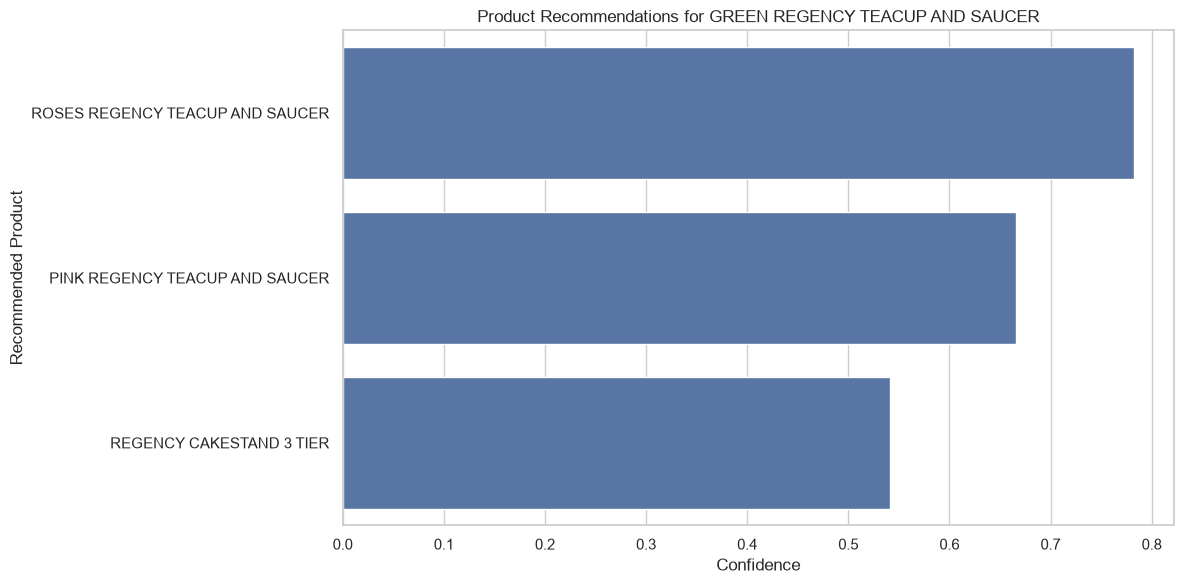

Saved chart: product_recommendations.png

PRODUCT RECOMMENDATION SYSTEM COMPLETED!


In [7]:
# ============================================================
# RETAIL CUSTOMER INTELLIGENCE
# STEP 14: PRODUCT RECOMMENDATION SYSTEM
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

print("=" * 70)
print("PRODUCT RECOMMENDATION SYSTEM")
print("=" * 70)

# ------------------------------------------------------------
# 1. LOAD ASSOCIATION RULES
# ------------------------------------------------------------

rules_path = Path("../data/processed/market_basket_rules.csv")

if not rules_path.exists():
    raise FileNotFoundError(
        f"Could not find {rules_path}. "
        "Check that your Market Basket Analysis outputs were saved."
    )

rules_df = pd.read_csv(rules_path)

print("\n1. ASSOCIATION RULES LOADED")
print(f"Total association rules: {len(rules_df):,}")
print("\nAvailable columns:")
print(rules_df.columns.tolist())

# ------------------------------------------------------------
# 2. PREPARE RULES FOR RECOMMENDATIONS
# ------------------------------------------------------------

required_columns = [
    "antecedents_text",
    "consequents_text",
    "support",
    "confidence",
    "lift"
]

missing_columns = [
    column for column in required_columns
    if column not in rules_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns in association rules: {missing_columns}"
    )

rules_df = rules_df.dropna(subset=required_columns).copy()

# Keep simple one-product -> one-product rules.
# This makes the recommendations easier to interpret.
rules_df = rules_df[
    ~rules_df["antecedents_text"].str.contains(",", regex=False)
    & ~rules_df["consequents_text"].str.contains(",", regex=False)
].copy()

# Retain positive associations with useful confidence.
rules_df = rules_df[
    (rules_df["lift"] > 1)
    & (rules_df["confidence"] >= 0.20)
].copy()

print("\n2. RECOMMENDATION RULES PREPARED")
print(f"One-product-to-one-product rules: {len(rules_df):,}")

# ------------------------------------------------------------
# 3. CREATE RECOMMENDATION FUNCTION
# ------------------------------------------------------------

def recommend_products(product_name, top_n=5):
    """
    Recommend products based on association rules.

    Parameters
    ----------
    product_name : str
        Exact product description to search for.
    top_n : int
        Maximum number of recommendations.

    Returns
    -------
    pandas.DataFrame
        Recommended products with support, confidence, and lift.
    """

    matches = rules_df[
        rules_df["antecedents_text"].str.casefold()
        == product_name.strip().casefold()
    ].copy()

    if matches.empty:
        # Allow partial matching when the exact product is not found.
        matches = rules_df[
            rules_df["antecedents_text"].str.contains(
                product_name,
                case=False,
                regex=False,
                na=False
            )
        ].copy()

    if matches.empty:
        print(f"\nNo recommendations found for: {product_name}")
        return pd.DataFrame(
            columns=[
                "input_product",
                "recommended_product",
                "support",
                "confidence",
                "lift"
            ]
        )

    # Prefer higher confidence and lift.
    matches = matches.sort_values(
        ["confidence", "lift", "support"],
        ascending=False
    )

    matches = matches.drop_duplicates(
        subset=["consequents_text"]
    ).head(top_n)

    recommendations = matches[
        [
            "antecedents_text",
            "consequents_text",
            "support",
            "confidence",
            "lift"
        ]
    ].rename(
        columns={
            "antecedents_text": "input_product",
            "consequents_text": "recommended_product"
        }
    )

    return recommendations.reset_index(drop=True)

# ------------------------------------------------------------
# 4. TEST THE RECOMMENDATION SYSTEM
# ------------------------------------------------------------

test_products = [
    "GREEN REGENCY TEACUP AND SAUCER",
    "PINK REGENCY TEACUP AND SAUCER",
    "SPACEBOY LUNCH BOX",
    "REGENCY CAKESTAND 3 TIER"
]

print("\n3. SAMPLE PRODUCT RECOMMENDATIONS")

for product in test_products:
    print("\n" + "-" * 70)
    print(f"INPUT PRODUCT: {product}")
    print("-" * 70)

    recommendations = recommend_products(product, top_n=5)

    if recommendations.empty:
        print("No matching recommendations.")
    else:
        print(
            recommendations[
                [
                    "recommended_product",
                    "support",
                    "confidence",
                    "lift"
                ]
            ].round(4).to_string(index=False)
        )

# ------------------------------------------------------------
# 5. SAVE RECOMMENDATIONS FOR ALL PRODUCTS
# ------------------------------------------------------------

all_recommendations = []

for product in rules_df["antecedents_text"].unique():
    recommendations = recommend_products(product, top_n=5)

    if not recommendations.empty:
        all_recommendations.append(recommendations)

if all_recommendations:
    recommendation_table = pd.concat(
        all_recommendations,
        ignore_index=True
    )

    recommendation_table = recommendation_table.drop_duplicates()

    output_dir = Path("../data/processed")
    output_dir.mkdir(parents=True, exist_ok=True)

    recommendation_table.to_csv(
        output_dir / "product_recommendations.csv",
        index=False
    )

    print("\n4. RECOMMENDATION OUTPUT")
    print(
        f"Total product recommendation rows: "
        f"{len(recommendation_table):,}"
    )
    print("Saved: product_recommendations.csv")

else:
    recommendation_table = pd.DataFrame()

    print("\nNo recommendations met the current filtering criteria.")

# ------------------------------------------------------------
# 6. VISUALISE SAMPLE RECOMMENDATIONS
# ------------------------------------------------------------

if not recommendation_table.empty:

    sample_product = "GREEN REGENCY TEACUP AND SAUCER"

    chart_data = recommendation_table[
        recommendation_table["input_product"].str.casefold()
        == sample_product.casefold()
    ].head(5).copy()

    if not chart_data.empty:

        plt.figure(figsize=(12, 6))

        sns.barplot(
            data=chart_data,
            x="confidence",
            y="recommended_product"
        )

        plt.title(
            f"Product Recommendations for {sample_product}"
        )
        plt.xlabel("Confidence")
        plt.ylabel("Recommended Product")
        plt.tight_layout()

        figure_dir = Path("../reports/figures")
        figure_dir.mkdir(parents=True, exist_ok=True)

        plt.savefig(
            figure_dir / "product_recommendations.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

        print("Saved chart: product_recommendations.png")

print("\nPRODUCT RECOMMENDATION SYSTEM COMPLETED!")

K-MEANS CUSTOMER CLUSTERING

1. CUSTOMER DATA LOADED
Customer records: 4,338
Columns: ['customerid', 'recency', 'frequency', 'monetary', 'last_purchase', 'R_score', 'F_score', 'M_score', 'RFM_score', 'segment']

2. FEATURE PREPARATION
Valid customers: 4,338
Features: ['recency', 'frequency', 'monetary']

3. LOG-TRANSFORMED FEATURE SUMMARY
        recency  frequency  monetary
count  4338.000   4338.000  4338.000
mean      3.857      1.346     6.589
std       1.307      0.683     1.258
min       0.693      0.693     1.558
25%       2.944      0.693     5.728
50%       3.951      1.099     6.507
75%       4.968      1.792     7.416
max       5.927      5.347    12.543

4. FEATURE STANDARDISATION
Features standardised successfully.

5. CLUSTER COUNT EVALUATION
K = 2 | Silhouette Score = 0.4325 | Inertia = 6476.51
K = 3 | Silhouette Score = 0.3363 | Inertia = 4858.24
K = 4 | Silhouette Score = 0.3329 | Inertia = 3925.43
K = 5 | Silhouette Score = 0.3181 | Inertia = 3269.27
K = 6 | Silhouett

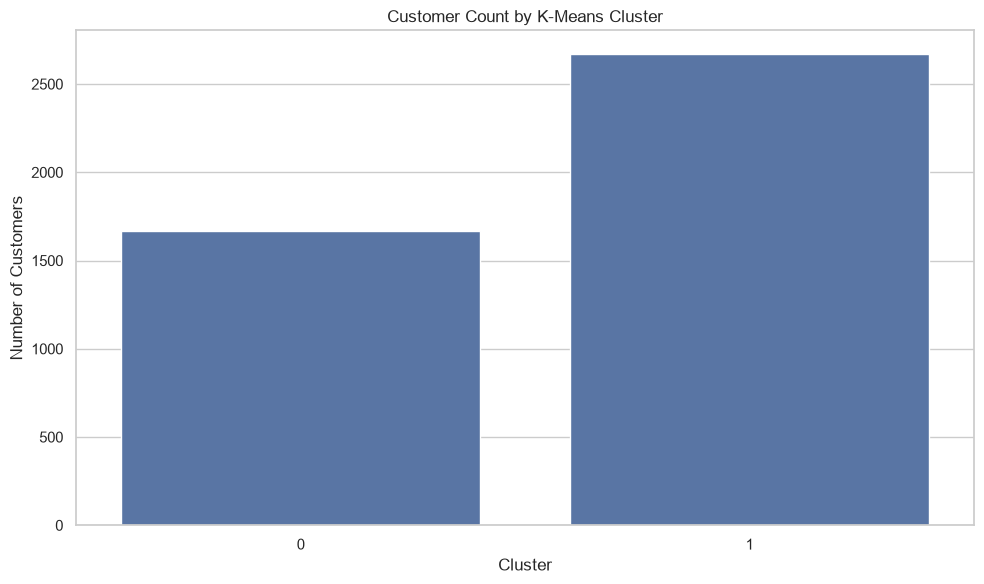

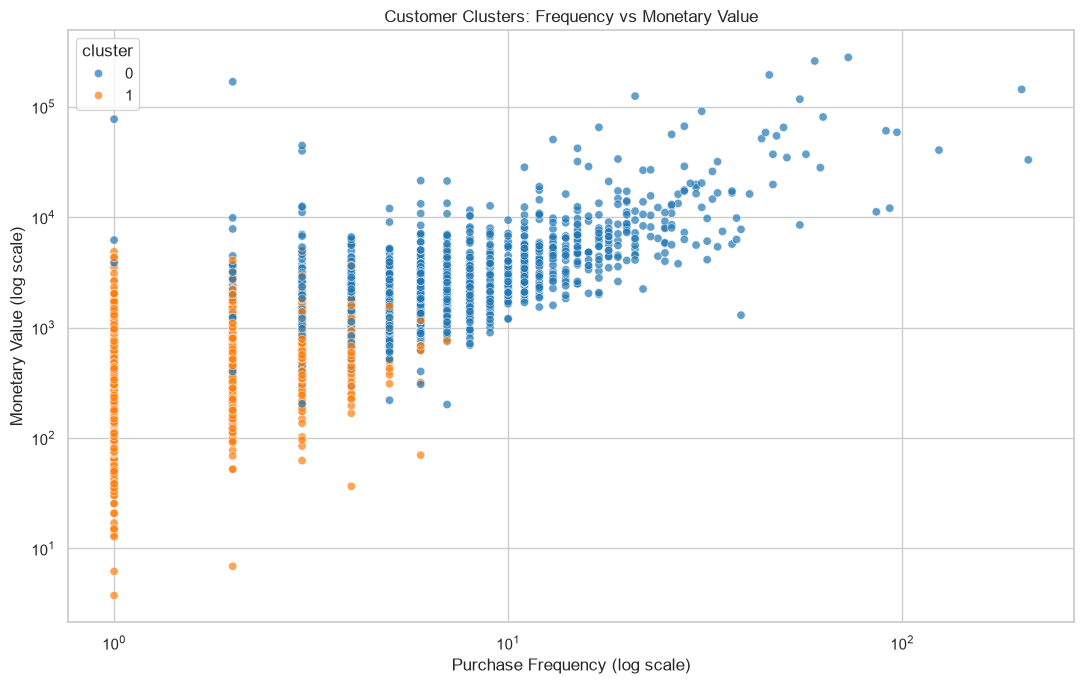


8. OUTPUT FILES
customer_clusters.csv
customer_cluster_profiles.csv
kmeans_cluster_evaluation.csv
kmeans_cluster_sizes.png
kmeans_frequency_monetary.png

K-MEANS CUSTOMER CLUSTERING COMPLETED!


In [8]:
# ============================================================
# RETAIL CUSTOMER INTELLIGENCE
# STEP 15: K-MEANS CUSTOMER CLUSTERING
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

print("=" * 70)
print("K-MEANS CUSTOMER CLUSTERING")
print("=" * 70)

# ------------------------------------------------------------
# 1. LOAD CUSTOMER FEATURES
# ------------------------------------------------------------

input_path = Path("../data/processed/customer_features.csv")

if not input_path.exists():
    raise FileNotFoundError(
        f"Could not find {input_path}. "
        "Check that your RFM analysis outputs were saved."
    )

customer_df = pd.read_csv(input_path)

print("\n1. CUSTOMER DATA LOADED")
print(f"Customer records: {len(customer_df):,}")
print(f"Columns: {customer_df.columns.tolist()}")

required_columns = [
    "customerid",
    "recency",
    "frequency",
    "monetary"
]

missing_columns = [
    col for col in required_columns
    if col not in customer_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# ------------------------------------------------------------
# 2. PREPARE FEATURES
# ------------------------------------------------------------

features = customer_df[
    ["recency", "frequency", "monetary"]
].copy()

features = features.replace(
    [np.inf, -np.inf],
    np.nan
)

valid_mask = (
    features.notna().all(axis=1)
    & (features["recency"] >= 0)
    & (features["frequency"] >= 1)
    & (features["monetary"] > 0)
)

customer_df = customer_df.loc[valid_mask].reset_index(drop=True)
features = features.loc[valid_mask].reset_index(drop=True)

print("\n2. FEATURE PREPARATION")
print(f"Valid customers: {len(features):,}")
print(f"Features: {features.columns.tolist()}")

# ------------------------------------------------------------
# 3. LOG TRANSFORMATION
# ------------------------------------------------------------

# Reduce skewness, especially in frequency and monetary values.
# Recency is also transformed to reduce the effect of extreme values.

features_log = np.log1p(features)

print("\n3. LOG-TRANSFORMED FEATURE SUMMARY")
print(features_log.describe().round(3))

# ------------------------------------------------------------
# 4. STANDARDISE FEATURES
# ------------------------------------------------------------

scaler = StandardScaler()

scaled_features = scaler.fit_transform(features_log)

print("\n4. FEATURE STANDARDISATION")
print("Features standardised successfully.")

# ------------------------------------------------------------
# 5. COMPARE DIFFERENT NUMBERS OF CLUSTERS
# ------------------------------------------------------------

print("\n5. CLUSTER COUNT EVALUATION")

cluster_results = []

for k in range(2, 8):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(scaled_features)

    score = silhouette_score(
        scaled_features,
        labels
    )

    cluster_results.append({
        "k": k,
        "silhouette_score": score,
        "inertia": model.inertia_
    })

    print(
        f"K = {k} | "
        f"Silhouette Score = {score:.4f} | "
        f"Inertia = {model.inertia_:.2f}"
    )

cluster_evaluation = pd.DataFrame(cluster_results)

# Select the k with the highest silhouette score.
best_k = int(
    cluster_evaluation.loc[
        cluster_evaluation["silhouette_score"].idxmax(),
        "k"
    ]
)

print(f"\nSelected number of clusters: {best_k}")

# ------------------------------------------------------------
# 6. TRAIN FINAL K-MEANS MODEL
# ------------------------------------------------------------

final_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

customer_df["cluster"] = final_model.fit_predict(
    scaled_features
)

print("\n6. FINAL CLUSTERING")
print(f"Number of clusters: {best_k}")

print("\nCustomers per cluster:")
print(
    customer_df["cluster"]
    .value_counts()
    .sort_index()
    .to_string()
)

# ------------------------------------------------------------
# 7. PROFILE CUSTOMER CLUSTERS
# ------------------------------------------------------------

cluster_profile = (
    customer_df.groupby("cluster")
    .agg(
        customer_count=("customerid", "nunique"),
        average_recency=("recency", "mean"),
        average_frequency=("frequency", "mean"),
        average_monetary=("monetary", "mean"),
        median_recency=("recency", "median"),
        median_frequency=("frequency", "median"),
        median_monetary=("monetary", "median"),
        total_monetary=("monetary", "sum")
    )
    .reset_index()
)

cluster_profile["customer_percentage"] = (
    cluster_profile["customer_count"]
    / customer_df["customerid"].nunique()
    * 100
).round(2)

numeric_columns = [
    "average_recency",
    "average_frequency",
    "average_monetary",
    "median_recency",
    "median_frequency",
    "median_monetary",
    "total_monetary"
]

cluster_profile[numeric_columns] = (
    cluster_profile[numeric_columns].round(2)
)

print("\n7. CUSTOMER CLUSTER PROFILES")
print(cluster_profile.to_string(index=False))

# ------------------------------------------------------------
# 8. VISUALISE CLUSTER SIZES
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.countplot(
    data=customer_df,
    x="cluster"
)

plt.title("Customer Count by K-Means Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()

figure_dir = Path("../reports/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_dir / "kmeans_cluster_sizes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 9. VISUALISE FREQUENCY AND MONETARY VALUE
# ------------------------------------------------------------

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=customer_df,
    x="frequency",
    y="monetary",
    hue="cluster",
    palette="tab10",
    alpha=0.7
)

plt.yscale("log")
plt.xscale("log")

plt.title("Customer Clusters: Frequency vs Monetary Value")
plt.xlabel("Purchase Frequency (log scale)")
plt.ylabel("Monetary Value (log scale)")
plt.tight_layout()

plt.savefig(
    figure_dir / "kmeans_frequency_monetary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 10. SAVE OUTPUTS
# ------------------------------------------------------------

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

customer_df.to_csv(
    output_dir / "customer_clusters.csv",
    index=False
)

cluster_profile.to_csv(
    output_dir / "customer_cluster_profiles.csv",
    index=False
)

cluster_evaluation.to_csv(
    output_dir / "kmeans_cluster_evaluation.csv",
    index=False
)

print("\n8. OUTPUT FILES")
print("customer_clusters.csv")
print("customer_cluster_profiles.csv")
print("kmeans_cluster_evaluation.csv")
print("kmeans_cluster_sizes.png")
print("kmeans_frequency_monetary.png")

print("\nK-MEANS CUSTOMER CLUSTERING COMPLETED!")

RFM SEGMENTS VS K-MEANS CLUSTERS

1. DATASETS LOADED
RFM customers: 4,338
Cluster customers: 4,338

2. MERGE VALIDATION
Matched customers: 4,338
RFM customers without a matching cluster: 0
Cluster customers without a matching RFM record: 0

3. CUSTOMER COUNTS BY RFM SEGMENT AND CLUSTER
cluster                         0     1   All
segment                                      
Frequent Customers            364   201   565
High-Value Loyal              941     0   941
Occasional Customers           31   524   555
Potentially Inactive            3  1069  1072
Previously Active Customers     8   403   411
Recent Customers               29   281   310
Recent and Engaged            292   192   484
All                          1668  2670  4338

4. CLUSTER DISTRIBUTION WITHIN EACH RFM SEGMENT (%)
cluster                           0      1
segment                                   
Frequent Customers            64.42  35.58
High-Value Loyal             100.00   0.00
Occasional Customers        

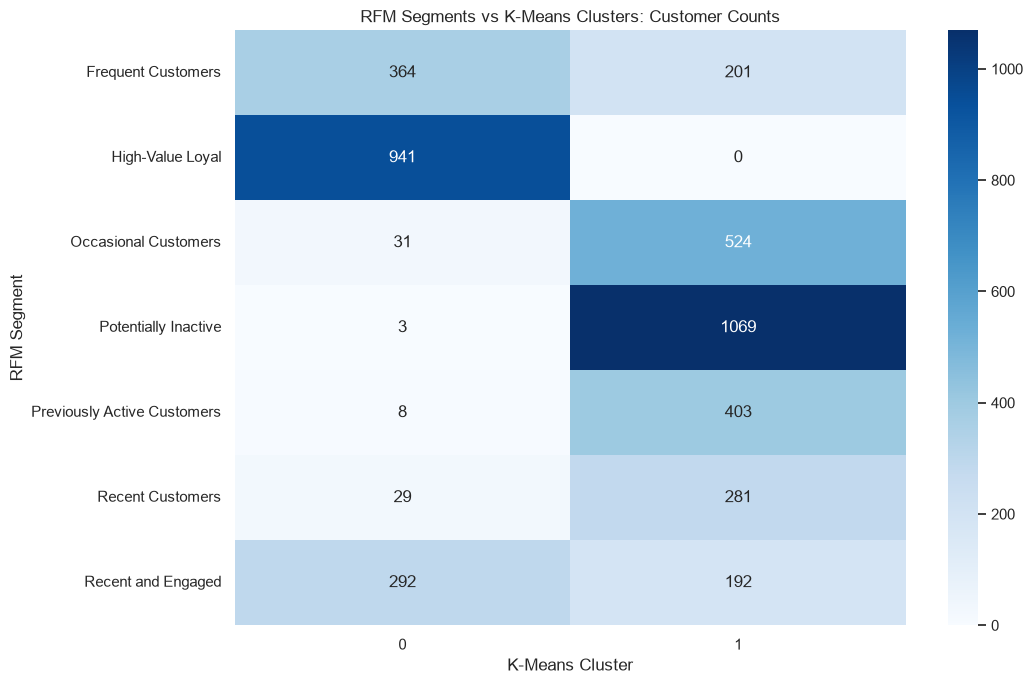

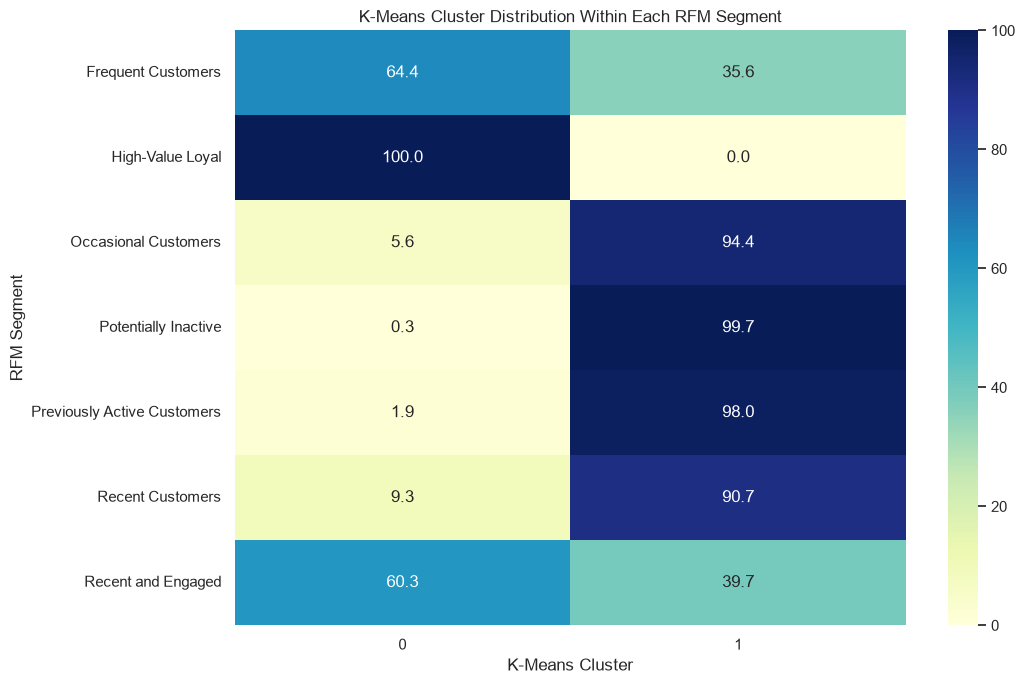


6. OUTPUT FILES
rfm_kmeans_count_comparison.csv
rfm_kmeans_row_percentages.csv
rfm_kmeans_column_percentages.csv
rfm_kmeans_customer_comparison.csv
rfm_vs_kmeans_counts.png
rfm_vs_kmeans_percentages.png

RFM VS K-MEANS COMPARISON COMPLETED!


In [9]:
# ============================================================
# RETAIL CUSTOMER INTELLIGENCE
# STEP 16: RFM VS K-MEANS COMPARISON
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

print("=" * 70)
print("RFM SEGMENTS VS K-MEANS CLUSTERS")
print("=" * 70)

# ------------------------------------------------------------
# 1. LOAD THE TWO DATASETS
# ------------------------------------------------------------

input_dir = Path("../data/processed")

rfm_path = input_dir / "customer_features.csv"
cluster_path = input_dir / "customer_clusters.csv"

if not rfm_path.exists():
    raise FileNotFoundError(f"File not found: {rfm_path}")

if not cluster_path.exists():
    raise FileNotFoundError(f"File not found: {cluster_path}")

rfm_data = pd.read_csv(rfm_path)
cluster_data = pd.read_csv(cluster_path)

print("\n1. DATASETS LOADED")
print(f"RFM customers: {len(rfm_data):,}")
print(f"Cluster customers: {len(cluster_data):,}")

# ------------------------------------------------------------
# 2. VALIDATE CUSTOMER IDS
# ------------------------------------------------------------

rfm_data["customerid"] = rfm_data["customerid"].astype(str)
cluster_data["customerid"] = cluster_data["customerid"].astype(str)

if rfm_data["customerid"].duplicated().any():
    raise ValueError("Duplicate customer IDs found in RFM data.")

if cluster_data["customerid"].duplicated().any():
    raise ValueError("Duplicate customer IDs found in cluster data.")

# Keep only the columns needed for comparison.
rfm_subset = rfm_data[
    ["customerid", "segment"]
].copy()

cluster_subset = cluster_data[
    ["customerid", "cluster"]
].copy()

# ------------------------------------------------------------
# 3. MERGE THE DATASETS
# ------------------------------------------------------------

comparison = rfm_subset.merge(
    cluster_subset,
    on="customerid",
    how="inner",
    validate="one_to_one"
)

print("\n2. MERGE VALIDATION")
print(f"Matched customers: {len(comparison):,}")
print(
    "RFM customers without a matching cluster: "
    f"{len(rfm_subset) - len(comparison):,}"
)
print(
    "Cluster customers without a matching RFM record: "
    f"{len(cluster_subset) - len(comparison):,}"
)

if len(comparison) == 0:
    raise ValueError("No customers matched between the two datasets.")

# ------------------------------------------------------------
# 4. CROSS-TABULATION: CUSTOMER COUNTS
# ------------------------------------------------------------

print("\n3. CUSTOMER COUNTS BY RFM SEGMENT AND CLUSTER")

count_table = pd.crosstab(
    comparison["segment"],
    comparison["cluster"],
    margins=True
)

print(count_table.to_string())

# ------------------------------------------------------------
# 5. ROW PERCENTAGES
# ------------------------------------------------------------

# Each row shows how a particular RFM segment is distributed
# across the K-Means clusters.

row_percentage = (
    pd.crosstab(
        comparison["segment"],
        comparison["cluster"],
        normalize="index"
    ) * 100
).round(2)

print("\n4. CLUSTER DISTRIBUTION WITHIN EACH RFM SEGMENT (%)")
print(row_percentage.to_string())

# ------------------------------------------------------------
# 6. COLUMN PERCENTAGES
# ------------------------------------------------------------

# Each column shows the RFM segment composition of a cluster.

column_percentage = (
    pd.crosstab(
        comparison["segment"],
        comparison["cluster"],
        normalize="columns"
    ) * 100
).round(2)

print("\n5. RFM SEGMENT COMPOSITION WITHIN EACH CLUSTER (%)")
print(column_percentage.to_string())

# ------------------------------------------------------------
# 7. VISUALISE CUSTOMER COUNTS
# ------------------------------------------------------------

plt.figure(figsize=(11, 7))

sns.heatmap(
    pd.crosstab(
        comparison["segment"],
        comparison["cluster"]
    ),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("RFM Segments vs K-Means Clusters: Customer Counts")
plt.xlabel("K-Means Cluster")
plt.ylabel("RFM Segment")
plt.tight_layout()

figure_dir = Path("../reports/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_dir / "rfm_vs_kmeans_counts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 8. VISUALISE ROW PERCENTAGES
# ------------------------------------------------------------

plt.figure(figsize=(11, 7))

sns.heatmap(
    row_percentage,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("K-Means Cluster Distribution Within Each RFM Segment")
plt.xlabel("K-Means Cluster")
plt.ylabel("RFM Segment")
plt.tight_layout()

plt.savefig(
    figure_dir / "rfm_vs_kmeans_percentages.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 9. SAVE COMPARISON OUTPUTS
# ------------------------------------------------------------

count_table.to_csv(
    input_dir / "rfm_kmeans_count_comparison.csv"
)

row_percentage.to_csv(
    input_dir / "rfm_kmeans_row_percentages.csv"
)

column_percentage.to_csv(
    input_dir / "rfm_kmeans_column_percentages.csv"
)

comparison.to_csv(
    input_dir / "rfm_kmeans_customer_comparison.csv",
    index=False
)

print("\n6. OUTPUT FILES")
print("rfm_kmeans_count_comparison.csv")
print("rfm_kmeans_row_percentages.csv")
print("rfm_kmeans_column_percentages.csv")
print("rfm_kmeans_customer_comparison.csv")
print("rfm_vs_kmeans_counts.png")
print("rfm_vs_kmeans_percentages.png")

print("\nRFM VS K-MEANS COMPARISON COMPLETED!")

In [10]:
# ============================================================
# RETAIL CUSTOMER INTELLIGENCE
# STEP 17: EXECUTIVE CUSTOMER ANALYSIS SUMMARY
# ============================================================

import pandas as pd
from pathlib import Path

print("=" * 70)
print("EXECUTIVE CUSTOMER ANALYSIS SUMMARY")
print("=" * 70)

# ------------------------------------------------------------
# 1. LOAD ANALYSIS OUTPUTS
# ------------------------------------------------------------

input_dir = Path("../data/processed")

rfm_summary_path = input_dir / "customer_segment_summary.csv"
cluster_profile_path = input_dir / "customer_cluster_profiles.csv"
comparison_path = input_dir / "rfm_kmeans_count_comparison.csv"

for path in [
    rfm_summary_path,
    cluster_profile_path,
    comparison_path
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Required file not found: {path}"
        )

rfm_summary = pd.read_csv(rfm_summary_path)
cluster_profile = pd.read_csv(cluster_profile_path)
comparison_counts = pd.read_csv(
    comparison_path,
    index_col=0
)

print("\n1. INPUT FILES LOADED")
print(f"RFM segments: {len(rfm_summary)}")
print(f"K-Means clusters: {len(cluster_profile)}")

# ------------------------------------------------------------
# 2. PREPARE RFM BUSINESS SUMMARY
# ------------------------------------------------------------

rfm_business = rfm_summary[
    [
        "segment",
        "customer_count",
        "customer_percentage",
        "average_recency",
        "average_frequency",
        "average_monetary",
        "total_monetary"
    ]
].copy()

rfm_business["analysis_type"] = "RFM Segment"

rfm_business = rfm_business.rename(
    columns={
        "segment": "group_name",
        "customer_count": "customers",
        "customer_percentage": "customer_percentage",
        "average_recency": "avg_recency_days",
        "average_frequency": "avg_frequency",
        "average_monetary": "avg_monetary",
        "total_monetary": "total_monetary"
    }
)

# ------------------------------------------------------------
# 3. PREPARE K-MEANS BUSINESS SUMMARY
# ------------------------------------------------------------

cluster_business = cluster_profile[
    [
        "cluster",
        "customer_count",
        "customer_percentage",
        "average_recency",
        "average_frequency",
        "average_monetary",
        "total_monetary"
    ]
].copy()

cluster_business["analysis_type"] = "K-Means Cluster"

cluster_business["group_name"] = (
    "Cluster " + cluster_business["cluster"].astype(str)
)

cluster_business = cluster_business.rename(
    columns={
        "customer_count": "customers",
        "average_recency": "avg_recency_days",
        "average_frequency": "avg_frequency",
        "average_monetary": "avg_monetary"
    }
)

cluster_business = cluster_business[
    [
        "analysis_type",
        "group_name",
        "customers",
        "customer_percentage",
        "avg_recency_days",
        "avg_frequency",
        "avg_monetary",
        "total_monetary"
    ]
]

# ------------------------------------------------------------
# 4. COMBINE THE SUMMARIES
# ------------------------------------------------------------

rfm_business = rfm_business[
    [
        "analysis_type",
        "group_name",
        "customers",
        "customer_percentage",
        "avg_recency_days",
        "avg_frequency",
        "avg_monetary",
        "total_monetary"
    ]
]

executive_summary = pd.concat(
    [rfm_business, cluster_business],
    ignore_index=True
)

numeric_columns = [
    "customer_percentage",
    "avg_recency_days",
    "avg_frequency",
    "avg_monetary",
    "total_monetary"
]

executive_summary[numeric_columns] = (
    executive_summary[numeric_columns].round(2)
)

print("\n2. EXECUTIVE CUSTOMER SUMMARY")
print(executive_summary.to_string(index=False))

# ------------------------------------------------------------
# 5. CREATE RFM-TO-CLUSTER ALIGNMENT TABLE
# ------------------------------------------------------------

alignment = comparison_counts.drop(
    index="All",
    columns="All",
    errors="ignore"
)

alignment_percentage = (
    alignment.div(alignment.sum(axis=1), axis=0) * 100
).round(2)

print("\n3. RFM-TO-K-MEANS ALIGNMENT (%)")
print(alignment_percentage.to_string())

# ------------------------------------------------------------
# 6. SAVE REPORTS
# ------------------------------------------------------------

executive_summary.to_csv(
    input_dir / "executive_customer_summary.csv",
    index=False
)

alignment_percentage.to_csv(
    input_dir / "executive_rfm_cluster_alignment.csv"
)

print("\n4. OUTPUT FILES")
print("executive_customer_summary.csv")
print("executive_rfm_cluster_alignment.csv")

print("\nEXECUTIVE CUSTOMER ANALYSIS SUMMARY COMPLETED!")

EXECUTIVE CUSTOMER ANALYSIS SUMMARY

1. INPUT FILES LOADED
RFM segments: 7
K-Means clusters: 2

2. EXECUTIVE CUSTOMER SUMMARY
  analysis_type                  group_name  customers  customer_percentage  avg_recency_days  avg_frequency  avg_monetary  total_monetary
    RFM Segment        Potentially Inactive       1072                24.71            217.47           1.10        488.07       523208.53
    RFM Segment            High-Value Loyal        941                21.69             12.98          11.21       6101.93      5741913.58
    RFM Segment          Frequent Customers        565                13.02             85.44           5.47       2196.97      1241287.38
    RFM Segment        Occasional Customers        555                12.79             52.84           1.61        608.02       337452.79
    RFM Segment          Recent and Engaged        484                11.16             16.27           2.96       1088.77       526962.74
    RFM Segment Previously Active Custom